## 1. Bibliotecas e parâmetros

In [75]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from pathlib import Path
from sklearn.cluster import KMeans
from scipy import ndimage
from collections import deque


K = 3           # K principal: usado nas seções 3 a 7 e na morfologia
PESO_XY = 0.5   # peso principal do RGB+XY: usado nas seções 4 a 7 e na morfologia
MAX_LADO = None # Ex.: 450 para testes rápidos. None mantém a resolução original.



LISTA_PESOS = [0.25, 0.5, 0.75, 1.0, 2.0]   # o peso 0 (RGB) entra automaticamente

image_path = Path('/content/2or4objects.jpg')


## 2. Leitura da imagem e preparação RGB

Imagem: (531, 700, 3)
Pixels RGB: (371700, 3)


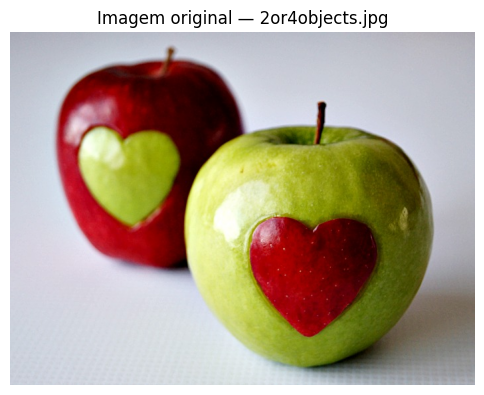

In [76]:
# Se o arquivo não estiver no Colab, permite enviá-lo pela interface.
if not image_path.exists():
    try:
        from google.colab import files
        uploaded = files.upload()
        if not uploaded:
            raise FileNotFoundError('Nenhuma imagem foi enviada.')
        image_path = Path(next(iter(uploaded)))
    except ImportError as exc:
        raise FileNotFoundError(
            f'Imagem não encontrada em {image_path}. Ajuste image_path.'
        ) from exc

imagemRGB = Image.open(image_path).convert('RGB')
if MAX_LADO is not None:
    imagemRGB.thumbnail((MAX_LADO, MAX_LADO))

imagemArray = np.array(imagemRGB)
altura, largura, _ = imagemArray.shape
imagemAchatada = imagemArray.reshape(-1, 3).astype(np.float32)

print('Imagem:', imagemArray.shape)
print('Pixels RGB:', imagemAchatada.shape)

plt.figure(figsize=(6, 5))
plt.imshow(imagemArray)
plt.title(f'Imagem original — {image_path.name}')
plt.axis('off')
plt.show()

## 3. Segmentação K-means com RGB

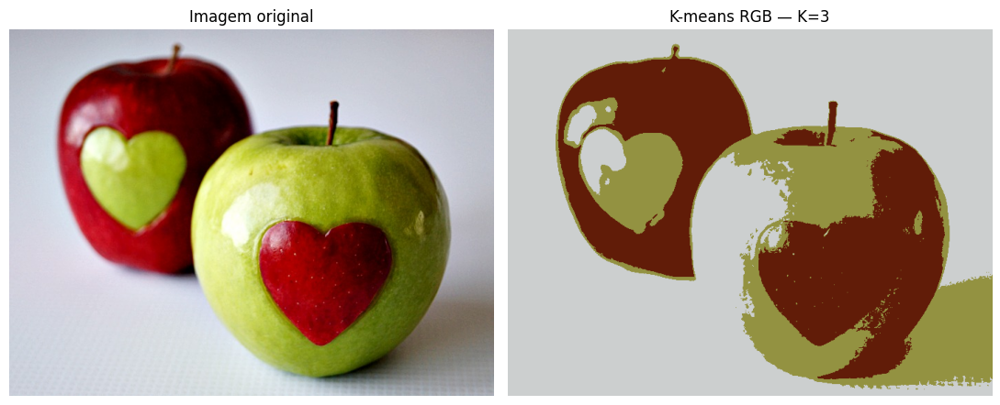

In [77]:
kmeans = KMeans(n_clusters=K, random_state=42, n_init=10)
rotulos = kmeans.fit_predict(imagemAchatada)
centroides = kmeans.cluster_centers_

# Cada rótulo aponta para a cor RGB média (centroide) do grupo.
imagemSegmentada = centroides[rotulos].reshape(altura, largura, 3)
imagemSegmentada = np.clip(imagemSegmentada, 0, 255).astype(np.uint8)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].imshow(imagemArray)
axes[0].set_title('Imagem original')
axes[1].imshow(imagemSegmentada)
axes[1].set_title(f'K-means RGB — K={K}')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

## 4. Coordenadas e segmentação K-means RGB+XY

cria as coordenadas X e Y de cada pixel, coloca na mesma escala das cores (0–255), multiplica pelo peso e junta às cores: cada pixel passa a ter 5 valores (R, G, B, X, Y). Depois roda o K-means nesse espaço.
Com a posição, pixels próximos na imagem tendem a ficar no mesmo cluster. O peso controla quanto a posição pesa em relação à cor.

In [78]:
# meshgrid retorna diretamente matrizes (altura, largura), sem transposição.
MatrizX, MatrizY = np.meshgrid(np.arange(largura), np.arange(altura))
MatrizX = MatrizX.reshape(-1, 1)
MatrizY = MatrizY.reshape(-1, 1)

# As cores RGB estão na escala 0–255; normalizamos XY à mesma escala.
MatrizXNormalizada = MatrizX.astype(np.float32) / max(largura - 1, 1) * 255
MatrizYNormalizada = MatrizY.astype(np.float32) / max(altura - 1, 1) * 255

# PESO_XY controla a influência espacial em relação às cores.
imagemRGBXY = np.hstack((
    imagemAchatada,
    MatrizXNormalizada * PESO_XY,
    MatrizYNormalizada * PESO_XY
))

assert imagemRGBXY.shape == (altura * largura, 5)
print('Formato RGB+XY:', imagemRGBXY.shape)
print('Cinco primeiras linhas [R, G, B, X ponderado, Y ponderado]:')
print(imagemRGBXY[:5])

# Mesma quantidade de clusters do K-means RGB.
kmeansRGBXY = KMeans(n_clusters=K, random_state=42, n_init=10)
rotulosRGBXY = kmeansRGBXY.fit_predict(imagemRGBXY)
centroidesRGBXY = kmeansRGBXY.cluster_centers_

# Apenas os primeiros 3 valores dos centroides são cores.
cores_centroidesRGBXY = centroidesRGBXY[:, :3]
imagemSegmentadaRGBXY = cores_centroidesRGBXY[rotulosRGBXY].reshape(altura, largura, 3)
imagemSegmentadaRGBXY = np.clip(imagemSegmentadaRGBXY, 0, 255).astype(np.uint8)

Formato RGB+XY: (371700, 5)
Cinco primeiras linhas [R, G, B, X ponderado, Y ponderado]:
[[1.6800000e+02 1.7000000e+02 1.8200000e+02 0.0000000e+00 0.0000000e+00]
 [1.6700000e+02 1.6900000e+02 1.8100000e+02 1.8240345e-01 0.0000000e+00]
 [1.6700000e+02 1.6900000e+02 1.8100000e+02 3.6480689e-01 0.0000000e+00]
 [1.6800000e+02 1.7000000e+02 1.8200000e+02 5.4721028e-01 0.0000000e+00]
 [1.6900000e+02 1.7100000e+02 1.8300000e+02 7.2961378e-01 0.0000000e+00]]


## 5. Comparação visual: original × RGB × RGB+XY

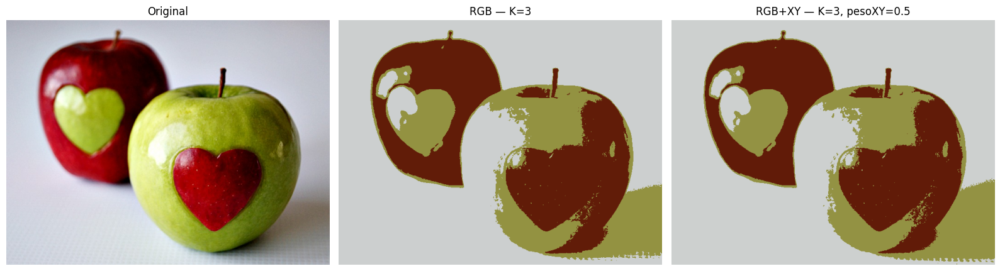

In [79]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, img, titulo in zip(
    axes,
    [imagemArray, imagemSegmentada, imagemSegmentadaRGBXY],
    ['Original', f'RGB — K={K}', f'RGB+XY — K={K}, pesoXY={PESO_XY}']
):
    ax.imshow(img)
    ax.set_title(titulo)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 6. Gráfico de dispersão 3D no espaço RGB

desenha uma amostra de 4.000 pixels no espaço RGB (um eixo por canal), coloridos pelo cluster, com os centroides marcados.
Mostra que os pixels formam faixas que vão do escuro ao claro (mesma cor em brilhos diferentes), o que explica por que o K-means separa brilho além de cor.

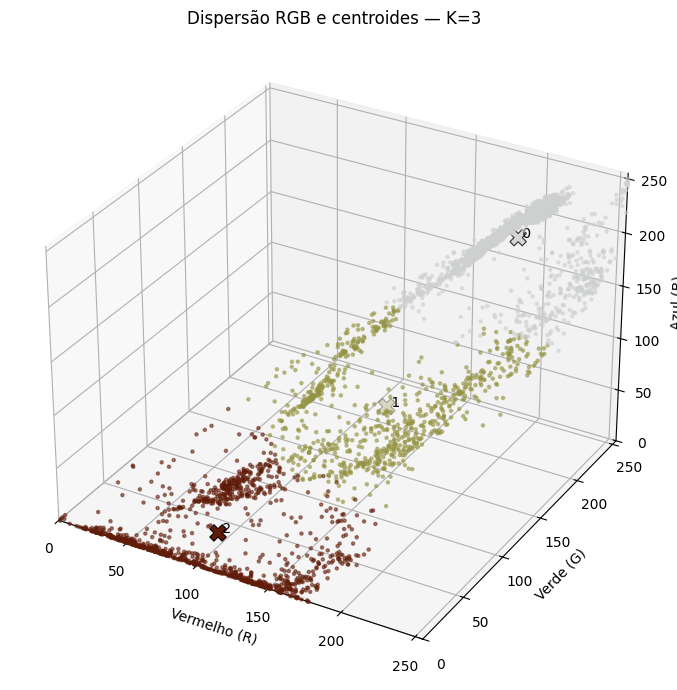

In [80]:
amostra = min(4000, imagemAchatada.shape[0])
rng = np.random.default_rng(42)
indices = rng.choice(imagemAchatada.shape[0], size=amostra, replace=False)
pontos = imagemAchatada[indices]
clusters_amostra = rotulos[indices]
cores_amostra = np.clip(centroides[clusters_amostra] / 255.0, 0, 1)

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(
    pontos[:, 0], pontos[:, 1], pontos[:, 2],
    c=cores_amostra, s=5, alpha=0.55
)
ax.scatter(
    centroides[:, 0], centroides[:, 1], centroides[:, 2],
    c=np.clip(centroides / 255.0, 0, 1),
    s=140, marker='X', edgecolors='black', linewidths=0.8
)
for indice, centro in enumerate(centroides):
    ax.text(centro[0], centro[1], centro[2], f' {indice}', fontsize=10)
ax.set_xlabel('Vermelho (R)')
ax.set_ylabel('Verde (G)')
ax.set_zlabel('Azul (B)')
ax.set_xlim(0, 255)
ax.set_ylim(0, 255)
ax.set_zlim(0, 255)
ax.set_title(f'Dispersão RGB e centroides — K={K}')
plt.tight_layout()
plt.show()

## 7. Identificar os clusters antes de criar máscaras

Cada **cluster** agrupa pixels, não reconhece sozinho uma maçã. Observe as máscaras abaixo e escolha **um ou mais índices** correspondentes às regiões das maçãs. Não assuma que o cluster `0` é uma maçã ou o fundo. Os números dos clusters RGB não correspondem necessariamente aos números RGB+XY.

Centroides RGB:
RGB cluster 0: [205 208 207]
RGB cluster 1: [148 147  66]
RGB cluster 2: [97 28  9]

Centroides RGB+XY (somente os 3 componentes de cor):
RGB+XY cluster 0: [205 208 207]
RGB+XY cluster 1: [147 147  68]
RGB+XY cluster 2: [98 28  9]


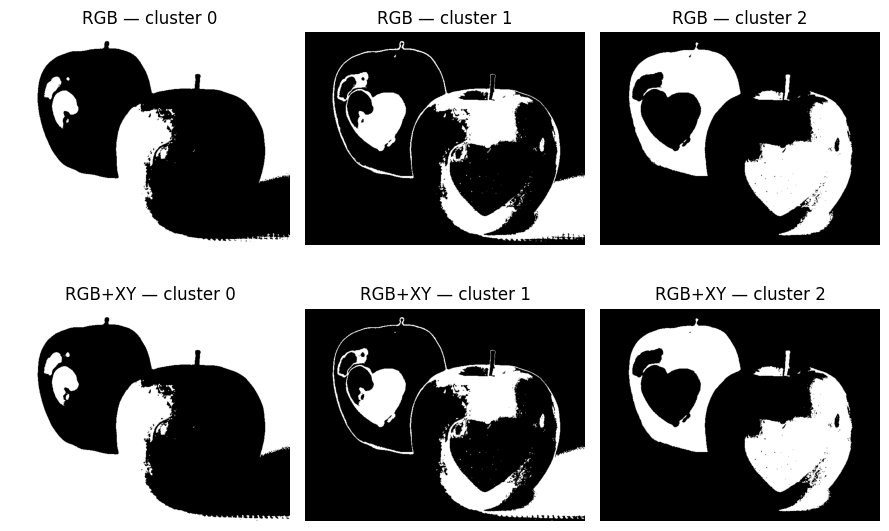

In [81]:
print('Centroides RGB:')
for indice, centro in enumerate(centroides):
    print(f'RGB cluster {indice}: {np.rint(centro).astype(int)}')
print()
print('Centroides RGB+XY (somente os 3 componentes de cor):')
for indice, centro in enumerate(cores_centroidesRGBXY):
    print(f'RGB+XY cluster {indice}: {np.rint(centro).astype(int)}')

fig, axes = plt.subplots(2, K, figsize=(max(9, 2.7 * K), 6), squeeze=False)
for cluster in range(K):
    mascara_cluster_rgb = (rotulos == cluster).reshape(altura, largura)
    mascara_cluster_rgbxy = (rotulosRGBXY == cluster).reshape(altura, largura)
    axes[0, cluster].imshow(mascara_cluster_rgb, cmap='gray', vmin=0, vmax=1)
    axes[1, cluster].imshow(mascara_cluster_rgbxy, cmap='gray', vmin=0, vmax=1)
    axes[0, cluster].set_title(f'RGB — cluster {cluster}')
    axes[1, cluster].set_title(f'RGB+XY — cluster {cluster}')
    for fila in range(2):
        axes[fila, cluster].axis('off')
plt.tight_layout()
plt.show()

## 8. Máscara de referência das maçãs

A referência é a região correta das duas maçãs (incluindo o coração recortado), desenhada como dois polígonos. Ela é o critério para comparar as configurações: o **IoU** mede quanto a máscara obtida coincide com ela.

Os vértices abaixo são uma **aproximação inicial**: confira o contorno amarelo na sobreposição e ajuste os pontos lendo as coordenadas na grade. Se `MAX_LADO` mudar, os pontos precisam ser redesenhados.

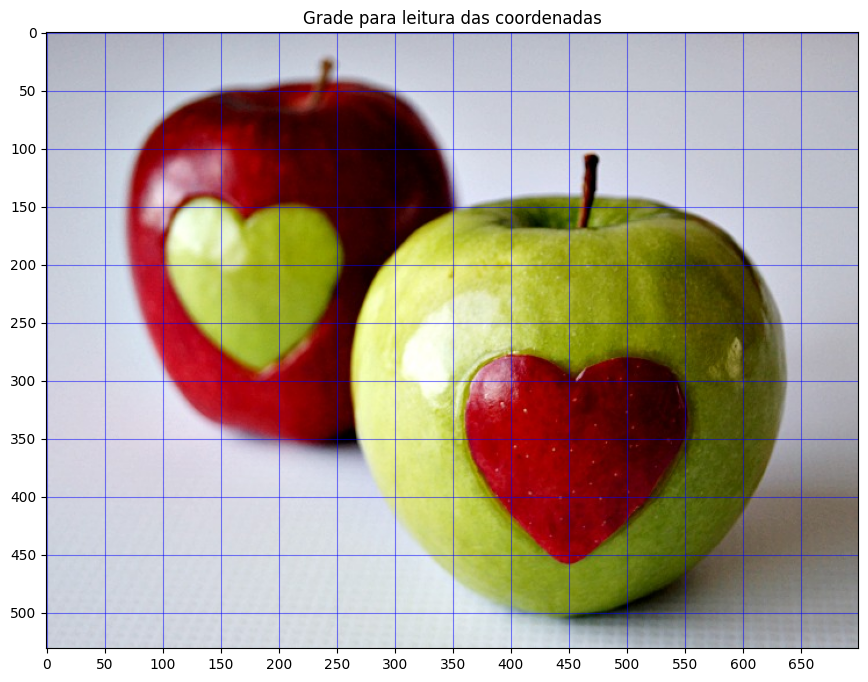

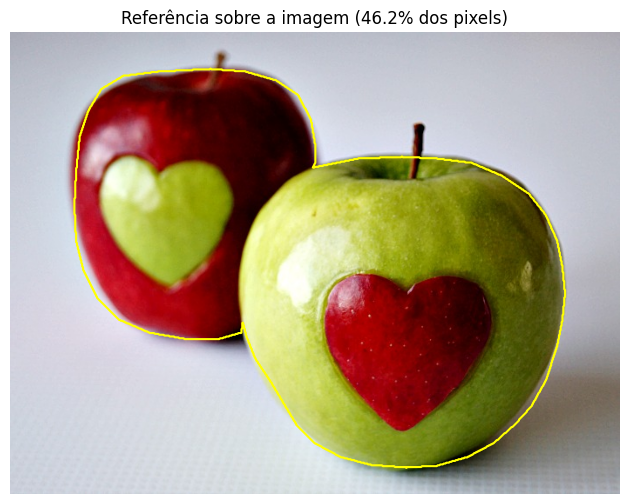

In [82]:
# Grade para ler as coordenadas (x, y) dos vértices
fig, ax = plt.subplots(figsize=(11, 8))
ax.imshow(imagemArray)
ax.set_xticks(range(0, largura, 50))
ax.set_yticks(range(0, altura, 50))
ax.grid(color='blue', alpha=0.5)
ax.set_title('Grade para leitura das coordenadas')
plt.show()

poligonoMacaVermelha = [(130,50),(170,45),(230,42),(270,45),(305,55),(330,72),(345,100),(350,130),(350,150),
                        (330,185),(290,230),(270,300),(265,345),(240,352),(200,352),(160,345),(125,330),
                        (100,305),(85,275),(76,240),(74,200),(76,160),(80,120),(90,90),(105,65)]
poligonoMacaVerde = [(350,155),(400,145),(450,143),(490,145),(530,150),(565,165),(595,185),(615,210),(628,240),
                     (634,270),(637,300),(634,330),(628,360),(615,400),(598,430),(580,450),(555,472),(525,488),
                     (490,498),(455,500),(415,497),(380,488),(350,472),(330,452),(300,402),(282,375),(272,350),
                     (264,320),(262,290),(265,255),(272,225),(282,200),(300,178),(325,163)]

tela = Image.new('L', (largura, altura), 0)
desenho = ImageDraw.Draw(tela)
desenho.polygon(poligonoMacaVermelha, fill=255)
desenho.polygon(poligonoMacaVerde, fill=255)
referencia = np.array(tela) > 0

fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(imagemArray)
ax.contour(referencia, levels=[0.5], colors='yellow', linewidths=1.5)
ax.set_title(f'Referência sobre a imagem ({100 * referencia.mean():.1f}% dos pixels)')
ax.axis('off')
plt.show()

## 9. Indicadores e varredura do peso XY

Indicadores usados (somente os necessários para decidir os parâmetros):

- **% por cluster:** mostra como K foi distribuído (ex.: se o fundo ocupa mais de um cluster).
- **Variância intra-cluster em cor e em posição:** medidas no mesmo espaço para todas as configurações. Ao aumentar o peso, a variância de posição cai (clusters compactos) e a de cor sobe (clusters menos homogêneos).
- **Inércia (apenas RGB):** comparável só dentro do mesmo espaço; usada para a curva de K.
- **Componentes e fragmentos < 100 px da máscara:** quantidade de pedaços e de ruído, que a morfologia deverá tratar.
- **IoU com a referência:** critério para escolher K e peso.

A máscara das maçãs é obtida por regra: o fundo é o cluster com mais pixels na borda da imagem, e os demais clusters formam a máscara. Esta seção executa, para o **K atual**, o K-means RGB e o RGB+XY com cada peso de `LISTA_PESOS`. K é alterado manualmente, um de cada vez: os resultados **se acumulam** entre execuções (imagem, K e peso identificam cada linha). Para recomeçar, reinicie o ambiente de execução.

In [83]:
posicaoNormalizada = np.hstack((MatrizX / max(largura - 1, 1), MatrizY / max(altura - 1, 1)))  # x e y em 0–1

def varianciaIntra(dados, rotulosConfig, k):
    total = 0.0
    for cluster in range(k):
        pontos = dados[rotulosConfig == cluster]
        if len(pontos) > 0:
            total += ((pontos - pontos.mean(axis=0)) ** 2).sum()
    return total / len(dados)

def clusterDeFundo(rotulosImagem, k):
    borda = np.concatenate([rotulosImagem[0, :], rotulosImagem[-1, :],
                            rotulosImagem[:, 0], rotulosImagem[:, -1]])
    return int(np.bincount(borda, minlength=k).argmax())

def calcularIoU(mascara, ref):
    intersecao = np.logical_and(mascara, ref).sum()
    uniao = np.logical_or(mascara, ref).sum()
    return intersecao / uniao

def calcularIndicadores(rotulosConfig, k, inercia, peso):
    rotulosImagem = rotulosConfig.reshape(altura, largura)
    proporcao = np.bincount(rotulosConfig, minlength=k) / rotulosConfig.size

    mascara = rotulosImagem != clusterDeFundo(rotulosImagem, k)
    rotulados, componentes = ndimage.label(mascara, structure=np.ones((3, 3)))
    areas = np.bincount(rotulados.ravel())[1:]

    return {
        '% por cluster': ' / '.join(f'{100 * p:.0f}' for p in proporcao),
        'var. intra cor': round(varianciaIntra(imagemAchatada, rotulosConfig, k), 1),
        'var. intra posição (x1000)': round(1000 * varianciaIntra(posicaoNormalizada, rotulosConfig, k), 1),
        'inércia (só RGB)': f'{inercia:.4g}' if peso == 0 else '-',
        'componentes': componentes,
        'fragmentos < 100 px': int((areas < 100).sum()),
        'IoU': round(calcularIoU(mascara, referencia), 3) if referencia is not None else np.nan,
    }, mascara

if 'REGISTRO' not in globals():
    REGISTRO = {}
if 'RESULTADOS' not in globals():
    RESULTADOS = {}

para o K atual, roda o K-means em RGB e em RGB+XY com cada peso da lista, calcula os indicadores e acumula tudo numa tabela (as linhas de execuções anteriores, com outro K ou outra imagem, continuam).
é a varredura que decide K e peso pelo IoU. A tabela final é a evidência usada no relatório.

In [84]:
for peso in [0] + LISTA_PESOS:
    if peso == 0:
        dados, nomeConfig = imagemAchatada, 'RGB'
    else:
        dados = np.hstack((imagemAchatada, MatrizXNormalizada * peso, MatrizYNormalizada * peso))
        nomeConfig = f'RGB+XY peso={peso}'

    modelo = KMeans(n_clusters=K, random_state=42, n_init=10).fit(dados)
    indicadores, mascara = calcularIndicadores(modelo.labels_, K, modelo.inertia_, peso)

    chave = (image_path.name, K, peso)
    RESULTADOS[chave] = {'rotulos': modelo.labels_, 'cores': modelo.cluster_centers_[:, :3],
                         'mascara': mascara, 'IoU': indicadores['IoU']}
    REGISTRO[chave] = {'imagem': image_path.name, 'K': K, 'configuração': nomeConfig, **indicadores}
    print(f'K={K:<2} {nomeConfig:<18} IoU={indicadores["IoU"]}')

pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 20)
display(pd.DataFrame(list(REGISTRO.values())))

K=3  RGB                IoU=0.735
K=3  RGB+XY peso=0.25   IoU=0.733
K=3  RGB+XY peso=0.5    IoU=0.726
K=3  RGB+XY peso=0.75   IoU=0.574
K=3  RGB+XY peso=1.0    IoU=0.503
K=3  RGB+XY peso=2.0    IoU=0.377


,imagem,K,configuração,% por cluster,var. intra cor,var. intra posição (x1000),inércia (só RGB),componentes,fragmentos < 100 px,IoU
0,2or4objects.jpg,3,RGB,55 / 19 / 25,2507.300049,160.5,9.319e+08,39,38,0.735
1,2or4objects.jpg,3,RGB+XY peso=0.25,25 / 55 / 19,2508.199951,160.0,-,33,32,0.733
2,2or4objects.jpg,3,RGB+XY peso=0.5,55 / 20 / 25,2522.899902,158.6,-,28,27,0.726
3,2or4objects.jpg,3,RGB+XY peso=0.75,29 / 40 / 32,4035.600098,107.3,-,42,40,0.574
4,2or4objects.jpg,3,RGB+XY peso=1.0,28 / 40 / 32,4150.899902,104.8,-,19,18,0.503
5,2or4objects.jpg,3,RGB+XY peso=2.0,41 / 31 / 29,10925.400391,75.0,-,24,20,0.377
6,variableObjects.jpeg,4,RGB,15 / 45 / 12 / 29,2336.800049,119.0,1.122e+09,7,6,0.387
7,variableObjects.jpeg,4,RGB+XY peso=0.5,15 / 30 / 39 / 16,2387.300049,99.4,-,7,6,0.354
8,variableObjects.jpeg,4,RGB+XY peso=1.0,20 / 30 / 21 / 29,4042.000000,67.6,-,2,1,0.310
9,variableObjects.jpeg,5,RGB,40 / 18 / 23 / 11 / 9,1706.699951,104.1,8.191e+08,9,8,0.361


## 10. Evidência — escolha de K

Compara os valores de K **já executados** para esta imagem (execute a seção 9 com cada K antes): segmentação RGB e RGB+XY (com `PESO_XY`), com o IoU no título, e a curva de inércia do K-means RGB.

K já executados para esta imagem: [3]


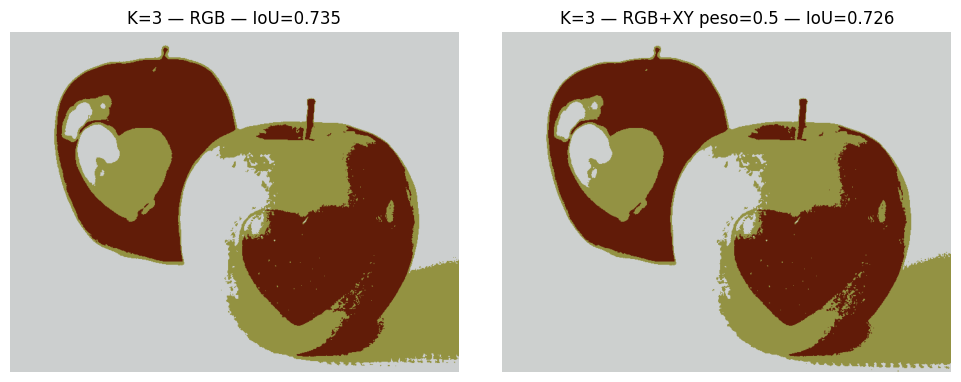

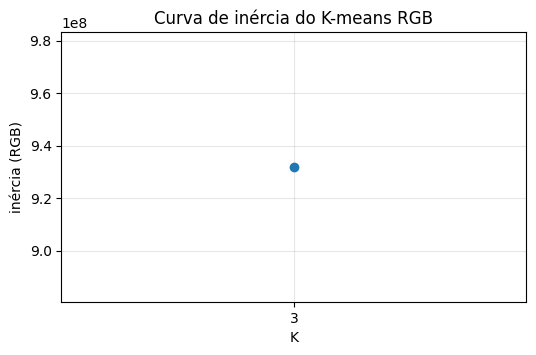

In [85]:
def imagemDosClusters(resultado):
    cores = np.clip(resultado['cores'], 0, 255)
    return cores[resultado['rotulos']].reshape(altura, largura, 3).astype(np.uint8)

ksExecutados = sorted({chave[1] for chave in RESULTADOS if chave[0] == image_path.name})
print('K já executados para esta imagem:', ksExecutados)

fig, axes = plt.subplots(len(ksExecutados), 2, figsize=(10, 3.8 * len(ksExecutados)), squeeze=False)
for linha, k in enumerate(ksExecutados):
    for coluna, (peso, nome) in enumerate([(0, 'RGB'), (PESO_XY, f'RGB+XY peso={PESO_XY}')]):
        resultado = RESULTADOS.get((image_path.name, k, peso))
        axes[linha, coluna].axis('off')
        if resultado is not None:
            axes[linha, coluna].imshow(imagemDosClusters(resultado))
            axes[linha, coluna].set_title(f'K={k} — {nome} — IoU={resultado["IoU"]}')
plt.tight_layout()
plt.show()

inercias = [float(REGISTRO[(image_path.name, k, 0)]['inércia (só RGB)']) for k in ksExecutados]
plt.figure(figsize=(6, 3.5))
plt.plot(ksExecutados, inercias, 'o-')
plt.xticks(ksExecutados)
plt.xlabel('K')
plt.ylabel('inércia (RGB)')
plt.title('Curva de inércia do K-means RGB')
plt.grid(alpha=0.3)
plt.show()

## 11. Evidência — escolha do peso XY (K principal)

Segmentações e máscaras das maçãs para cada peso (peso 0 = RGB), e as curvas de variância intra-cluster e de IoU em função do peso.

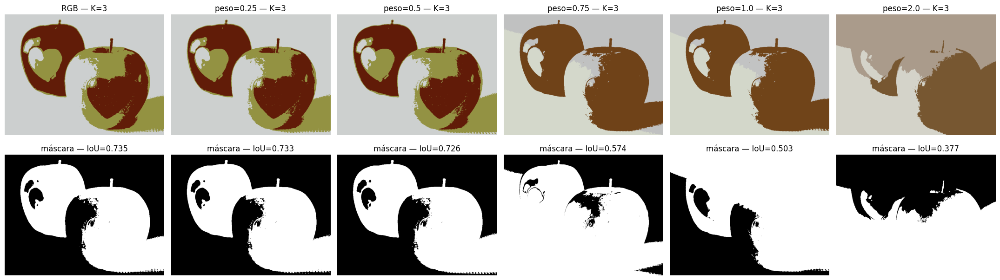

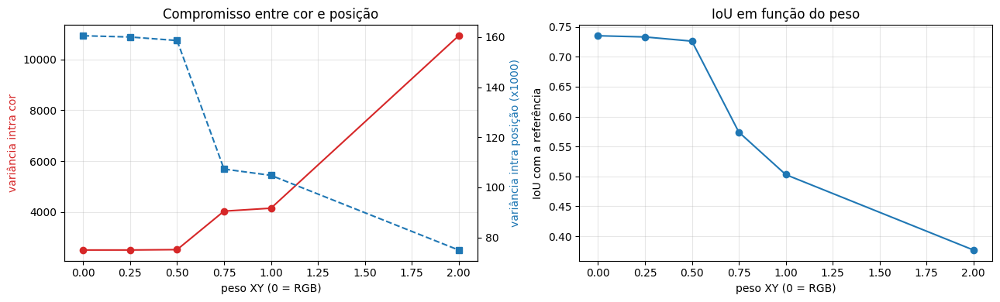

In [86]:
pesos = [0] + LISTA_PESOS
resultadosK = [RESULTADOS[(image_path.name, K, p)] for p in pesos]
titulos = ['RGB' if p == 0 else f'peso={p}' for p in pesos]

fig, axes = plt.subplots(2, len(pesos), figsize=(3.6 * len(pesos), 6.4))
for coluna, (resultado, titulo) in enumerate(zip(resultadosK, titulos)):
    axes[0, coluna].imshow(imagemDosClusters(resultado))
    axes[0, coluna].set_title(f'{titulo} — K={K}')
    axes[1, coluna].imshow(resultado['mascara'], cmap='gray', vmin=0, vmax=1)
    axes[1, coluna].set_title(f'máscara — IoU={resultado["IoU"]}')
for ax in axes.ravel():
    ax.axis('off')
plt.tight_layout()
plt.show()

linhasK = [REGISTRO[(image_path.name, K, p)] for p in pesos]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(pesos, [l['var. intra cor'] for l in linhasK], 'o-', color='tab:red', label='variância intra cor')
eixoPosicao = axes[0].twinx()
eixoPosicao.plot(pesos, [l['var. intra posição (x1000)'] for l in linhasK], 's--', color='tab:blue', label='variância intra posição (x1000)')
axes[0].set_xlabel('peso XY (0 = RGB)')
axes[0].set_ylabel('variância intra cor', color='tab:red')
eixoPosicao.set_ylabel('variância intra posição (x1000)', color='tab:blue')
axes[0].set_title('Compromisso entre cor e posição')
axes[1].plot(pesos, [l['IoU'] for l in linhasK], 'o-')
axes[1].set_xlabel('peso XY (0 = RGB)')
axes[1].set_ylabel('IoU com a referência')
axes[1].set_title('IoU em função do peso')
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Segunda Imagem: maças de vidro

In [87]:
image_path = Path('/content/variableObjects.jpeg')
MAX_LADO = 800                # 800x600: deixa o K-means rápido; os polígonos se ajustam sozinhos
LISTA_K_IMG2 = [4, 5]         # 3 maçãs + fundo = 4; o 5 testa se a sombra ganha cluster próprio
LISTA_PESOS = [0.5, 1.0]      # dois pesos bastam: um "fraco" e um "forte"
K = 4
PESO_XY = 0.5

Imagem: (600, 800, 3)
Pixels RGB: (480000, 3)


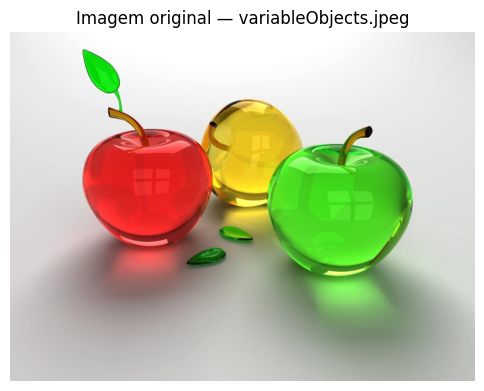

In [88]:
# Se o arquivo não estiver no Colab, permite enviá-lo pela interface.
if not image_path.exists():
    try:
        from google.colab import files
        uploaded = files.upload()
        if not uploaded:
            raise FileNotFoundError('Nenhuma imagem foi enviada.')
        image_path = Path(next(iter(uploaded)))
    except ImportError as exc:
        raise FileNotFoundError(
            f'Imagem não encontrada em {image_path}. Ajuste image_path.'
        ) from exc

imagemRGB = Image.open(image_path).convert('RGB')
if MAX_LADO is not None:
    imagemRGB.thumbnail((MAX_LADO, MAX_LADO))

imagemArray = np.array(imagemRGB)
altura, largura, _ = imagemArray.shape
imagemAchatada = imagemArray.reshape(-1, 3).astype(np.float32)

print('Imagem:', imagemArray.shape)
print('Pixels RGB:', imagemAchatada.shape)

plt.figure(figsize=(6, 5))
plt.imshow(imagemArray)
plt.title(f'Imagem original — {image_path.name}')
plt.axis('off')
plt.show()

In [31]:
# meshgrid retorna diretamente matrizes (altura, largura), sem transposição.
MatrizX, MatrizY = np.meshgrid(np.arange(largura), np.arange(altura))
MatrizX = MatrizX.reshape(-1, 1)
MatrizY = MatrizY.reshape(-1, 1)

# As cores RGB estão na escala 0–255; normalizamos XY à mesma escala.
MatrizXNormalizada = MatrizX.astype(np.float32) / max(largura - 1, 1) * 255
MatrizYNormalizada = MatrizY.astype(np.float32) / max(altura - 1, 1) * 255

# PESO_XY controla a influência espacial em relação às cores.
imagemRGBXY = np.hstack((
    imagemAchatada,
    MatrizXNormalizada * PESO_XY,
    MatrizYNormalizada * PESO_XY
))

assert imagemRGBXY.shape == (altura * largura, 5)
print('Formato RGB+XY:', imagemRGBXY.shape)
print('Cinco primeiras linhas [R, G, B, X ponderado, Y ponderado]:')
print(imagemRGBXY[:5])

# Mesma quantidade de clusters do K-means RGB.
kmeansRGBXY = KMeans(n_clusters=K, random_state=42, n_init=10)
rotulosRGBXY = kmeansRGBXY.fit_predict(imagemRGBXY)
centroidesRGBXY = kmeansRGBXY.cluster_centers_

# Apenas os primeiros 3 valores dos centroides são cores.
cores_centroidesRGBXY = centroidesRGBXY[:, :3]
imagemSegmentadaRGBXY = cores_centroidesRGBXY[rotulosRGBXY].reshape(altura, largura, 3)
imagemSegmentadaRGBXY = np.clip(imagemSegmentadaRGBXY, 0, 255).astype(np.uint8)

Formato RGB+XY: (480000, 5)
Cinco primeiras linhas [R, G, B, X ponderado, Y ponderado]:
[[2.3300000e+02 2.3300000e+02 2.3300000e+02 0.0000000e+00 0.0000000e+00]
 [2.3300000e+02 2.3300000e+02 2.3300000e+02 1.5957446e-01 0.0000000e+00]
 [2.3300000e+02 2.3300000e+02 2.3300000e+02 3.1914893e-01 0.0000000e+00]
 [2.3300000e+02 2.3300000e+02 2.3300000e+02 4.7872341e-01 0.0000000e+00]
 [2.3400000e+02 2.3400000e+02 2.3400000e+02 6.3829786e-01 0.0000000e+00]]


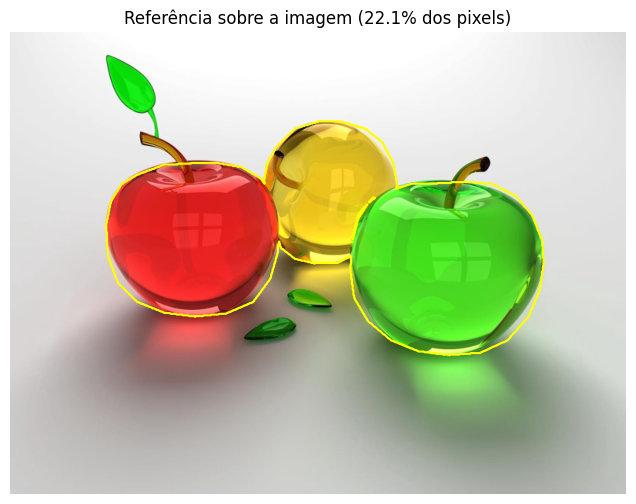

In [32]:
# Polígonos traçados na imagem original (1600x1200); a escala se ajusta ao tamanho usado
macaVermelha = [(330,370),(400,345),(470,340),(540,340),(600,350),(650,380),(685,430),(698,500),(695,570),(675,640),
                (630,700),(560,730),(480,738),(400,728),(330,700),(280,650),(255,580),(250,500),(262,440),(290,395)]
macaAmarela = [(668,340),(690,300),(740,250),(800,232),(860,232),(920,250),(965,285),(995,340),(1005,400),(990,420),
               (940,430),(905,470),(888,530),(885,580),(850,598),(790,600),(740,588),(705,560),(690,510),(670,440),(660,385)]
macaVerde = [(960,420),(1040,395),(1110,392),(1180,388),(1250,395),(1310,425),(1355,475),(1380,540),(1385,600),(1375,670),
             (1345,740),(1290,800),(1220,832),(1140,838),(1060,828),(990,800),(930,750),(895,690),(885,620),(888,550),(905,485),(930,445)]

escala = (largura / 1600, altura / 1200)
tela = Image.new('L', (largura, altura), 0)
desenho = ImageDraw.Draw(tela)
for poligono in (macaVermelha, macaAmarela, macaVerde):
    desenho.polygon([(x * escala[0], y * escala[1]) for x, y in poligono], fill=255)
referencia = np.array(tela) > 0

fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(imagemArray)
ax.contour(referencia, levels=[0.5], colors='yellow', linewidths=1.5)
ax.set_title(f'Referência sobre a imagem ({100 * referencia.mean():.1f}% dos pixels)')
ax.axis('off')
plt.show()

### Hipótese 1 — regra original do fundo
roda a varredura da imagem 2 (K = 4 e 5; RGB e pesos 0,5 e 1,0) com a regra original do fundo e acrescenta as linhas à tabela. As primeiras linhas recalculam as coordenadas para a imagem atual.
verificar as previsões feitas antes de rodar (sombra colorida, folhas, reflexos, XY, fundo em degradê).

In [34]:
# Coordenadas recalculadas para a imagem atual (evita usar o tamanho da imagem anterior)
MatrizX, MatrizY = np.meshgrid(np.arange(largura), np.arange(altura))
MatrizX, MatrizY = MatrizX.reshape(-1, 1), MatrizY.reshape(-1, 1)
MatrizXNormalizada = MatrizX.astype(np.float32) / max(largura - 1, 1) * 255
MatrizYNormalizada = MatrizY.astype(np.float32) / max(altura - 1, 1) * 255
posicaoNormalizada = np.hstack((MatrizX / max(largura - 1, 1), MatrizY / max(altura - 1, 1)))
for K in LISTA_K_IMG2:
    for peso in [0] + LISTA_PESOS:
        if peso == 0:
            dados, nomeConfig = imagemAchatada, 'RGB'
        else:
            dados = np.hstack((imagemAchatada, MatrizXNormalizada * peso, MatrizYNormalizada * peso))
            nomeConfig = f'RGB+XY peso={peso}'
        modelo = KMeans(n_clusters=K, random_state=42, n_init=10).fit(dados)
        indicadores, mascara = calcularIndicadores(modelo.labels_, K, modelo.inertia_, peso)
        chave = (image_path.name, K, peso)
        RESULTADOS[chave] = {'rotulos': modelo.labels_, 'cores': modelo.cluster_centers_[:, :3],
                             'mascara': mascara, 'IoU': indicadores['IoU']}
        REGISTRO[chave] = {'imagem': image_path.name, 'K': K, 'configuração': nomeConfig, **indicadores}
        print(f'K={K:<2} {nomeConfig:<18} IoU={indicadores["IoU"]}')
K = LISTA_K_IMG2[0]
display(pd.DataFrame(list(REGISTRO.values())))

K=4  RGB                IoU=0.387
K=4  RGB+XY peso=0.5    IoU=0.354
K=4  RGB+XY peso=1.0    IoU=0.31
K=5  RGB                IoU=0.361
K=5  RGB+XY peso=0.5    IoU=0.34
K=5  RGB+XY peso=1.0    IoU=0.299


,imagem,K,configuração,% por cluster,var. intra cor,var. intra posição (x1000),inércia (só RGB),componentes,fragmentos < 100 px,IoU
0,2or4objects.jpg,3,RGB,55 / 19 / 25,2507.300049,160.5,9.319e+08,39,38,0.735
1,2or4objects.jpg,3,RGB+XY peso=0.25,25 / 55 / 19,2508.199951,160.0,-,33,32,0.733
2,2or4objects.jpg,3,RGB+XY peso=0.5,55 / 20 / 25,2522.899902,158.6,-,28,27,0.726
3,2or4objects.jpg,3,RGB+XY peso=0.75,29 / 40 / 32,4035.600098,107.3,-,42,40,0.574
4,2or4objects.jpg,3,RGB+XY peso=1.0,28 / 40 / 32,4150.899902,104.8,-,19,18,0.503
5,2or4objects.jpg,3,RGB+XY peso=2.0,41 / 31 / 29,10925.400391,75.0,-,24,20,0.377
6,variableObjects.jpeg,4,RGB,15 / 45 / 12 / 29,2336.800049,119.0,1.122e+09,7,6,0.387
7,variableObjects.jpeg,4,RGB+XY peso=0.5,15 / 30 / 39 / 16,2387.300049,99.4,-,7,6,0.354
8,variableObjects.jpeg,4,RGB+XY peso=1.0,20 / 30 / 21 / 29,4042.000000,67.6,-,2,1,0.310
9,variableObjects.jpeg,5,RGB,40 / 18 / 23 / 11 / 9,1706.699951,104.1,8.191e+08,9,8,0.361


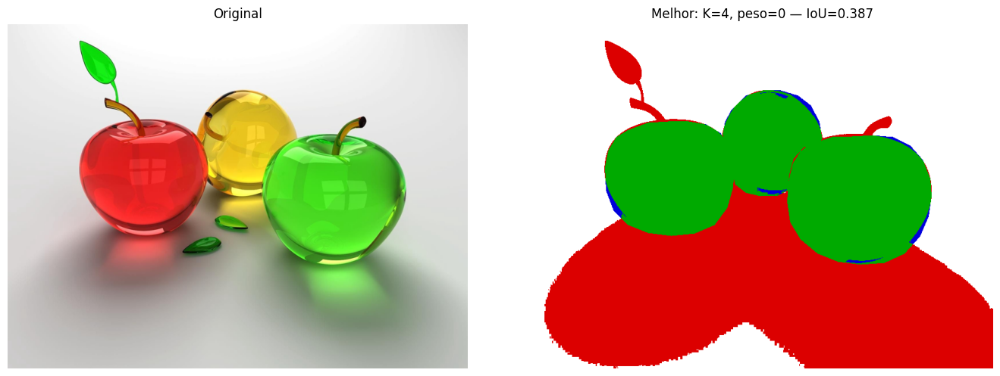

falso positivo: 153.0% da área da referência
maçã perdida:   2.1% da área da referência


In [35]:
melhor = max((c for c in RESULTADOS if c[0] == image_path.name), key=lambda c: RESULTADOS[c]['IoU'])
m = RESULTADOS[melhor]['mascara']
mapa = np.full((altura, largura, 3), 255, np.uint8)
mapa[m & referencia] = (0, 170, 0)      # verde: maçã encontrada
mapa[m & ~referencia] = (220, 0, 0)     # vermelho: falso positivo (sombra, folhas...)
mapa[~m & referencia] = (0, 0, 220)     # azul: maçã perdida (reflexos...)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(imagemArray); axes[0].set_title('Original')
axes[1].imshow(mapa)
axes[1].set_title(f'Melhor: K={melhor[1]}, peso={melhor[2]} — IoU={RESULTADOS[melhor]["IoU"]}')
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()
print(f'falso positivo: {100 * (m & ~referencia).sum() / referencia.sum():.1f}% da área da referência')
print(f'maçã perdida:   {100 * (~m & referencia).sum() / referencia.sum():.1f}% da área da referência')

### Hipótese 2 — regra da borda (≥ 10%) e máximo possível

nova regra do fundo: é fundo todo cluster com pelo menos 10% dos pixels da borda. Máximo possível: testa todas as combinações de clusters contra a referência e mostra o melhor IoU que qualquer regra conseguiria. Confere o que a regra nova faria na imagem 1.
separar o erro da regra do erro do agrupamento. Com K = 4 a regra nova chega a 0,725, igual ao máximo: o erro que sobra é da cor, não da regra. O máximo usa a referência, então é só diagnóstico. Na imagem 1 a regra nova só coincide com a original em RGB e peso baixo, por isso foi adotada só na imagem 2.

In [36]:
# H1: fundo = todo cluster com pelo menos 10% dos pixels da borda
# H2: limite do agrupamento = melhor combinação possível de clusters (usa a referência: só diagnóstico)
from itertools import combinations

def clustersDeFundo(rotulosImagem, k, minimo=0.10):
    borda = np.concatenate([rotulosImagem[0, :], rotulosImagem[-1, :], rotulosImagem[:, 0], rotulosImagem[:, -1]])
    fracao = np.bincount(borda, minlength=k) / borda.size
    return [c for c in range(k) if fracao[c] >= minimo]

def melhorCombinacao(rotulosImagem, k, ref):
    return max((calcularIoU(np.isin(rotulosImagem, grupo), ref), grupo)
               for n in range(1, k) for grupo in combinations(range(k), n))

print('Imagem 2 (variableObjects):')
for (img, k, peso), r in RESULTADOS.items():
    if img != image_path.name:
        continue
    rot = r['rotulos'].reshape(altura, largura)
    fundo = clustersDeFundo(rot, k)
    r['mascaraH1'] = ~np.isin(rot, fundo)
    r['IoU_H1'] = round(calcularIoU(r['mascaraH1'], referencia), 3)
    iouMax, grupo = melhorCombinacao(rot, k, referencia)
    print(f'K={k} peso={peso:<4} IoU original={r["IoU"]:.3f} | H1: fundo={fundo} IoU={r["IoU_H1"]:.3f} '
          f'| H2: máximo possível={iouMax:.3f} (maçã = clusters {grupo})')

print('\nImagem 1 (2or4objects): clusters com pelo menos 10% da borda')
for (img, k, peso), r in RESULTADOS.items():
    if img == '2or4objects.jpg':
        print(f'K={k} peso={peso:<4} fundo={clustersDeFundo(r["rotulos"].reshape(531, 700), k)}')

Imagem 2 (variableObjects):
K=4 peso=0    IoU original=0.387 | H1: fundo=[1, 3] IoU=0.725 | H2: máximo possível=0.725 (maçã = clusters (0, 2))
K=4 peso=0.5  IoU original=0.354 | H1: fundo=[1, 2] IoU=0.648 | H2: máximo possível=0.648 (maçã = clusters (0, 3))
K=4 peso=1.0  IoU original=0.310 | H1: fundo=[0, 1, 2] IoU=0.711 | H2: máximo possível=0.711 (maçã = clusters (3,))
K=5 peso=0    IoU original=0.361 | H1: fundo=[0, 2] IoU=0.557 | H2: máximo possível=0.660 (maçã = clusters (3, 4))
K=5 peso=0.5  IoU original=0.340 | H1: fundo=[0, 3] IoU=0.543 | H2: máximo possível=0.664 (maçã = clusters (1, 4))
K=5 peso=1.0  IoU original=0.299 | H1: fundo=[0, 3, 4] IoU=0.648 | H2: máximo possível=0.648 (maçã = clusters (1, 2))

Imagem 1 (2or4objects): clusters com pelo menos 10% da borda
K=3 peso=0    fundo=[0]
K=3 peso=0.25 fundo=[1]
K=3 peso=0.5  fundo=[0]
K=3 peso=0.75 fundo=[0, 2]
K=3 peso=1.0  fundo=[0, 2]
K=3 peso=2.0  fundo=[0, 1, 2]


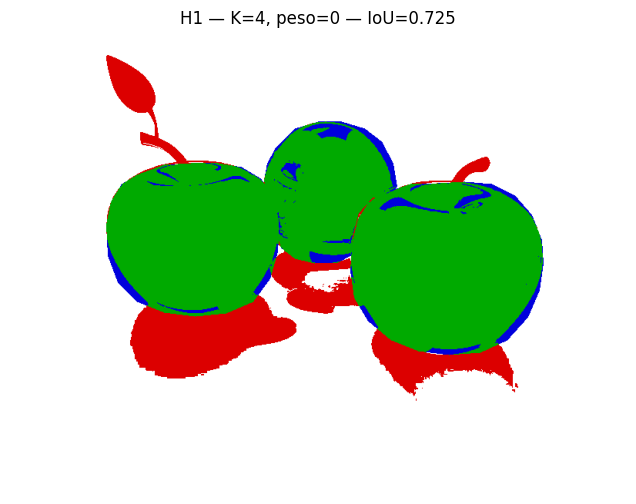

falso positivo: 28.2% da área da referência
maçã perdida:   7.1% da área da referência


In [37]:
melhorH1 = max((c for c in RESULTADOS if c[0] == image_path.name), key=lambda c: RESULTADOS[c]['IoU_H1'])
m = RESULTADOS[melhorH1]['mascaraH1']
mapa = np.full((altura, largura, 3), 255, np.uint8)
mapa[m & referencia] = (0, 170, 0); mapa[m & ~referencia] = (220, 0, 0); mapa[~m & referencia] = (0, 0, 220)
plt.figure(figsize=(8, 6)); plt.imshow(mapa); plt.axis('off')
plt.title(f'H1 — K={melhorH1[1]}, peso={melhorH1[2]} — IoU={RESULTADOS[melhorH1]["IoU_H1"]}')
plt.show()
print(f'falso positivo: {100 * (m & ~referencia).sum() / referencia.sum():.1f}% da área da referência')
print(f'maçã perdida:   {100 * (~m & referencia).sum() / referencia.sum():.1f}% da área da referência')

# Etapa 1 projeto 2

Aplicação de mascara manual para comparação de resultado

jovem (1024, 1024, 3) uint8
jovem_tinta (600, 400, 3) uint8
mulher (800, 712, 3) uint8
homem (1024, 1024, 3) uint8


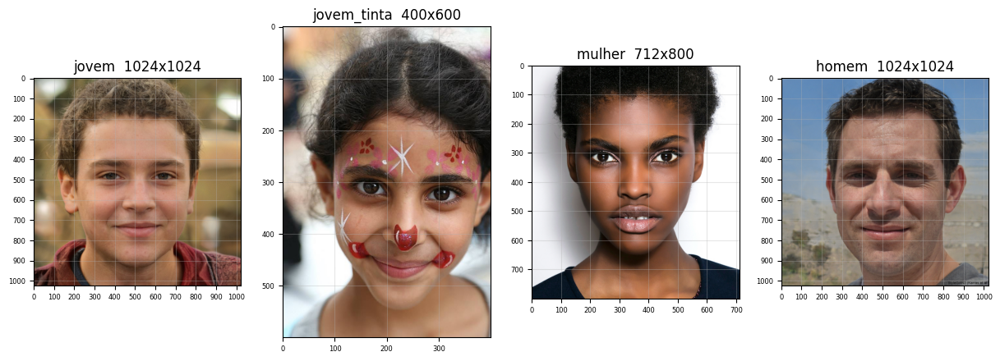

In [38]:
#Caminhos das imagens
CAMINHOS = {'jovem': "/content/face3.jpeg", 'jovem_tinta': "/content/face4.jpg", 'mulher': "/content/face2.jpg", 'homem': "/content/face1.jpg"}

IMGS = {}
for nome, caminho in CAMINHOS.items():
    img = np.array(Image.open(caminho).convert('RGB'))   # uint8, canais em ordem R, G, B
    print(nome, img.shape, img.dtype)
    IMGS[nome] = img

fig, ax = plt.subplots(1, 4, figsize=(15, 5.5))
for a, (nome, img) in zip(ax, IMGS.items()):
    a.imshow(img)
    a.set_title(f"{nome}  {img.shape[1]}x{img.shape[0]}")
    a.set_xticks(range(0, img.shape[1], 100)); a.set_yticks(range(0, img.shape[0], 100))
    a.tick_params(labelsize=6); a.grid(alpha=.3)
plt.show()


jovem ref=36.3%  lábios=2.9% da referência com lábios


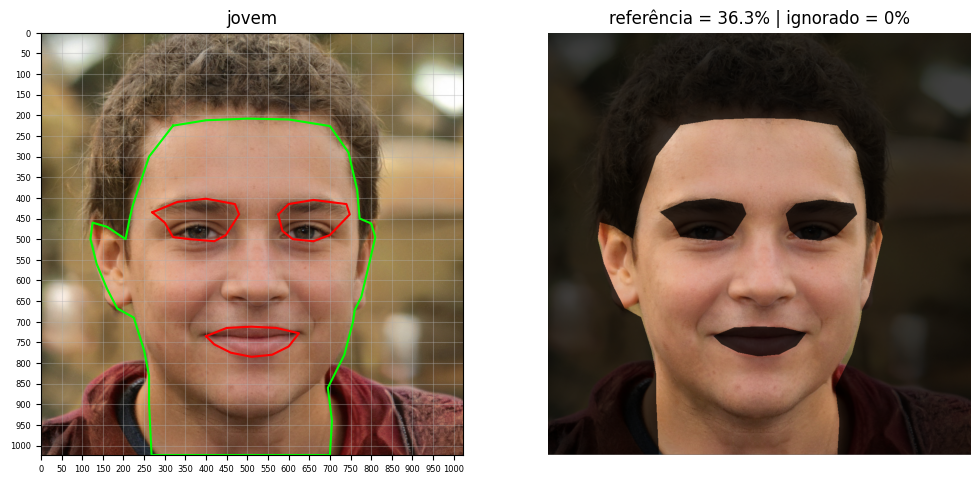

jovem_tinta ref=35.7%  lábios=3.3% da referência com lábios


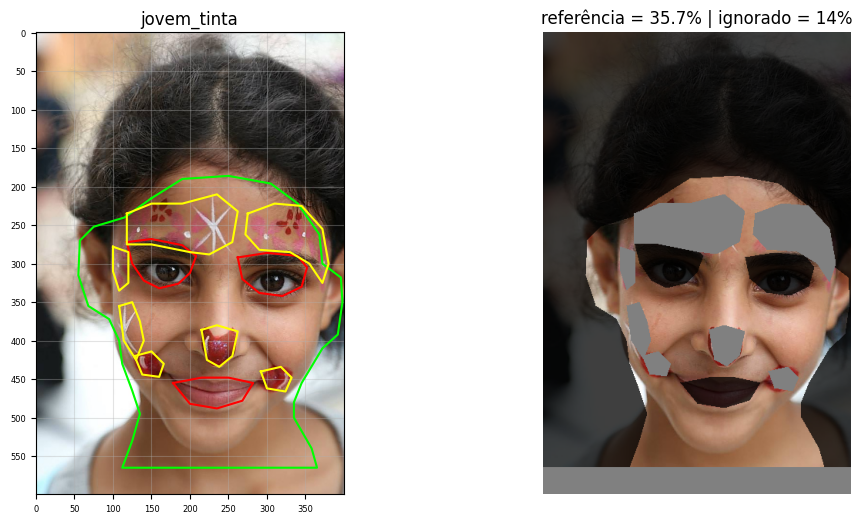

mulher ref=33.0%  lábios=5.9% da referência com lábios


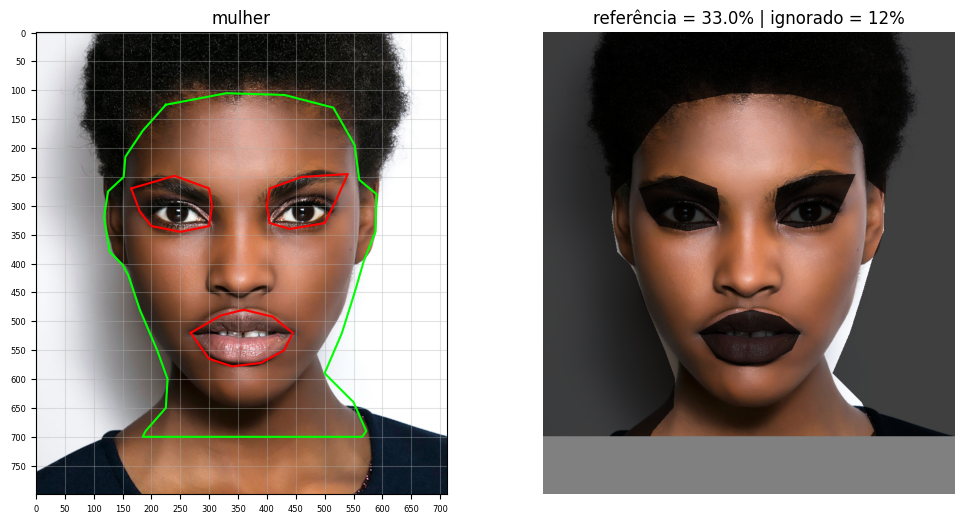

homem ref=38.5%  lábios=3.4% da referência com lábios


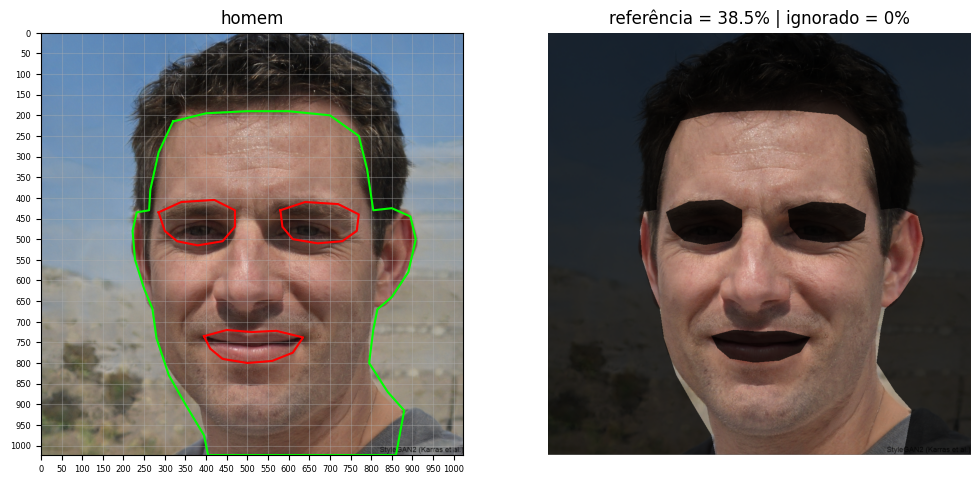

In [39]:

REFERENCIA = {
 'jovem': dict(
  pele=[(320, 225), (400, 212), (500, 208), (600, 210), (700, 226), (745, 290), (766, 380), (772, 450), (800, 462), (810, 495), (795, 560), (776, 640), (760, 672), (756, 700), (735, 780), (695, 860), (705, 940), (700, 1023), (268, 1023), (262, 900), (262, 830), (250, 770), (225, 690), (185, 668), (160, 620), (135, 560), (120, 500), (125, 460), (160, 470), (205, 500), (215, 450), (222, 420), (235, 380), (262, 300)],
  excl=[[(270, 435), (330, 410), (400, 402), (470, 415), (480, 440), (448, 490), (420, 505), (360, 500), (320, 495), (300, 460)], [(575, 440), (600, 415), (660, 405), (740, 415), (748, 440), (700, 490), (660, 505), (610, 500), (585, 480)]],   # olhos+sobrancelhas
  labios=[(400, 735), (450, 715), (510, 712), (570, 715), (625, 728), (600, 760), (560, 780), (510, 785), (460, 775), (420, 755)]),
  'jovem_tinta': dict(
  pele=[(150, 215), (115, 240), (75, 252), (57, 270), (55, 315), (68, 355), (95, 372), (108, 400), (112, 430), (125, 465), (135, 495), (125, 530), (112, 565), (365, 565), (358, 540), (335, 500), (335, 480), (345, 455), (360, 430), (372, 410), (392, 392), (398, 350), (396, 318), (372, 300), (368, 262), (340, 222), (305, 196), (250, 186), (190, 190)],
  excl=[[(118, 272), (150, 268), (190, 276), (208, 290), (200, 312), (185, 326), (160, 332), (140, 322), (125, 300)],
       [(262, 292), (300, 286), (340, 290), (352, 305), (345, 330), (320, 342), (290, 338), (268, 320)]],   # olhos+sobrancelhas
  tinta=[[(215, 386), (235, 380), (262, 388), (255, 420), (238, 434), (222, 425)],      # nariz
        [(128, 420), (150, 414), (166, 430), (160, 447), (138, 444)],                  # bochecha esq.
        [(292, 440), (318, 434), (332, 448), (324, 466), (300, 462)],                  # bochecha dir.
        [(108, 355), (125, 350), (135, 375), (140, 400), (130, 425), (114, 400)],      # estrela esq.
        [(118, 235), (150, 222), (190, 222), (235, 210), (262, 232), (255, 272), (225, 288), (200, 285), (150, 275), (118, 275)],  # testa esq.
        [(275, 235), (310, 222), (345, 225), (372, 255), (380, 300), (372, 325), (355, 300), (330, 285), (290, 282), (272, 262)],  # testa dir.
        [(100, 278), (120, 285), (120, 325), (108, 335), (100, 310)]],                 # têmpora esq.
  labios=[(178, 455), (215, 448), (250, 448), (282, 455), (268, 478), (235, 488), (200, 482)]),
 'mulher': dict(
  pele=[(225, 125), (185, 170), (155, 215), (152, 250), (125, 275), (118, 320), (128, 380), (150, 402), (160, 420), (180, 480), (210, 550), (228, 600), (225, 650), (190, 690), (185, 700), (565, 700), (572, 690), (550, 640), (500, 590), (530, 520), (552, 450), (568, 395), (588, 345), (590, 280), (560, 255), (552, 195), (515, 130), (430, 108), (330, 105)],
  excl=[[(165, 270), (240, 248), (300, 270), (305, 300), (300, 335), (250, 345), (200, 335), (180, 310)], [(400, 300), (405, 270), (460, 250), (540, 245), (520, 290), (500, 330), (440, 340), (405, 330)]],
  labios=[(268, 520), (320, 490), (360, 480), (410, 492), (445, 520), (430, 550), (390, 572), (340, 578), (300, 565)]),
 'homem': dict(
  pele=[(320, 215), (400, 195), (500, 190), (600, 190), (700, 200), (770, 250), (790, 330), (805, 430), (850, 425), (895, 445), (908, 500), (890, 580), (850, 640), (815, 670), (805, 720), (795, 800), (840, 870), (880, 915), (860, 1023), (405, 1023), (395, 975), (350, 900), (310, 830), (280, 740), (270, 668), (250, 620), (228, 550), (222, 480), (232, 435), (262, 430), (265, 380), (285, 290)],
  excl=[[(285, 435), (340, 410), (420, 405), (470, 430), (470, 470), (440, 505), (380, 515), (330, 505), (300, 480)], [(580, 430), (640, 410), (720, 415), (770, 440), (765, 480), (730, 505), (670, 510), (610, 500), (585, 470)]],
  labios=[(395, 735), (450, 720), (510, 725), (570, 722), (635, 738), (610, 775), (560, 795), (500, 800), (440, 790), (410, 765)]),
 }


def poligono_para_mascara(shape, vertices):
    """Regra par-ímpar: pixel dentro se um raio horizontal cruza um número ímpar de arestas."""
    h, w = shape
    Y, X = np.mgrid[0:h, 0:w]
    dentro = np.zeros((h, w), dtype=bool)
    n = len(vertices)
    for k in range(n):
        x1, y1 = vertices[k]
        x2, y2 = vertices[(k + 1) % n]
        if y1 == y2:                       # aresta horizontal não cruza o raio
            continue
        cruza = (y1 > Y) != (y2 > Y)       # a aresta atravessa a linha Y do pixel?
        x_inter = (x2 - x1) * (Y - y1) / (y2 - y1) + x1   # onde ela cruza em x
        dentro ^= cruza & (X < x_inter)    # inverte o estado a cada cruzamento à direita
    return dentro

def mascara_referencia(shape, ref, com_labios=False):
    m = poligono_para_mascara(shape, ref['pele'])
    for e in ref['excl']:
        m &= ~poligono_para_mascara(shape, e)
    if not com_labios:
        m &= ~poligono_para_mascara(shape, ref['labios'])
    return m

def regiao_ignorada(shape, ref):
    """Pixels fora da avaliação: tinta facial (cor não é de pele, mas cobre pele)
    e tudo abaixo da última linha anotada (pescoço/colo não anotados)."""
    ign = np.zeros(shape, dtype=bool)
    for t in ref.get('tinta', []):
        ign |= poligono_para_mascara(shape, t)
    corte = max(y for x, y in ref['pele'])
    ign[corte:, :] = True
    return ign

def mostrar_referencia(img, ref, m, titulo=""):
    ign = regiao_ignorada(img.shape[:2], ref)
    fig, ax = plt.subplots(1, 2, figsize=(12, 6))
    ax[0].imshow(img)
    contornos = [(ref['pele'], 'lime'), (ref['labios'], 'red')]
    contornos += [(e, 'red') for e in ref['excl']]
    contornos += [(t, 'yellow') for t in ref.get('tinta', [])]     # amarelo = ignorado
    for v, c in contornos:
        ax[0].plot(*zip(*(v + [v[0]])), color=c, lw=1.5)
    ax[0].set_xticks(range(0, img.shape[1], 50)); ax[0].set_yticks(range(0, img.shape[0], 50))
    ax[0].tick_params(labelsize=6); ax[0].grid(alpha=.35); ax[0].set_title(titulo)
    ov = img.copy(); ov[~m] = (ov[~m] * 0.25).astype(np.uint8)
    ov[ign] = (128, 128, 128)                                      # cinza = não avaliado
    ax[1].imshow(ov); ax[1].set_title(f"referência = {m.mean()*100:.1f}% | ignorado = {ign.mean()*100:.0f}%")
    ax[1].axis('off')
    plt.show()

MASCARAS = {}
for nome, img in IMGS.items():
    MASCARAS[nome] = mascara_referencia(img.shape[:2], REFERENCIA[nome])
    sem = mascara_referencia(img.shape[:2], REFERENCIA[nome], com_labios=True)
    print(nome, f"ref={MASCARAS[nome].mean()*100:.1f}%  lábios={(sem.sum()-MASCARAS[nome].sum())/sem.sum()*100:.1f}% da referência com lábios")
    mostrar_referencia(img, REFERENCIA[nome], MASCARAS[nome], nome)

Conversão e aplicação de regras

In [40]:
def rgb_para_hsv(img):
    """img RGB uint8 (h,w,3) -> H em graus [0,360), S em [0,1], V em [0,1]."""
    x = img.astype(np.float64) / 255.0
    r, g, b = x[..., 0], x[..., 1], x[..., 2]
    mx, mn = x.max(axis=-1), x.min(axis=-1)
    d = mx - mn
    H = np.zeros_like(mx)
    nz = d > 0
    m = nz & (mx == r)
    H[m] = (60 * (g[m] - b[m]) / d[m]) % 360
    m = nz & (mx == g) & (mx != r)
    H[m] = 60 * ((b[m] - r[m]) / d[m] + 2)
    m = nz & (mx == b) & (mx != r) & (mx != g)
    H[m] = 60 * ((r[m] - g[m]) / d[m] + 4)
    S = np.where(mx > 0, d / np.where(mx > 0, mx, 1), 0.0)
    return H, S, mx

def rgb_para_ycbcr(img):
    """Versão de 8 bits (com offset 128), a que os limiares do artigo pressupõem."""
    x = img.astype(np.float64)
    r, g, b = x[..., 0], x[..., 1], x[..., 2]
    Y = 0.299 * r + 0.587 * g + 0.114 * b
    Cr = 128 + 0.713 * (r - Y)
    Cb = 128 + 0.564 * (b - Y)
    return Y, Cb, Cr

def regra_rgb(img):
    r, g, b = [img[..., i].astype(np.float64) for i in range(3)]
    return (r > 95) & (g > 40) & (b > 20) & (r > g) & (r > b) & (np.abs(r - g) > 15)

def regra_hsv(img):
    H, S, V = rgb_para_hsv(img)
    return (H >= 0) & (H <= 50) & (S >= 0.23) & (S <= 0.68)

def regra_ycbcr(img):
    Y, Cb, Cr = rgb_para_ycbcr(img)
    return ((Cr > 135) & (Cb > 85) & (Y > 80) &
            (Cr <= 1.5862 * Cb + 20) & (Cr >= 0.3448 * Cb + 76.2069) &
            (Cr >= -4.5652 * Cb + 234.5652) & (Cr <= -1.15 * Cb + 301.75) &
            (Cr <= -2.2857 * Cb + 432.85))

def regra_artigo(img):
    rgb = regra_rgb(img)
    return (regra_hsv(img) & rgb) | (regra_ycbcr(img) & rgb)

REGRAS = {'RGB': regra_rgb, 'HSV': regra_hsv, 'YCbCr': regra_ycbcr, 'artigo': regra_artigo}

Faixa de borda e morfologia

In [41]:
def _dilata_eixo(m, r, eixo):
    h, w = m.shape
    pad = [(r, r) if i == eixo else (0, 0) for i in range(2)]
    p = np.pad(m, pad, constant_values=False)
    out = np.zeros_like(m)
    for k in range(2 * r + 1):
        out |= p[k:k + h, :] if eixo == 0 else p[:, k:k + w]
    return out

def dilatar(m, r):
    return _dilata_eixo(_dilata_eixo(m, r, 0), r, 1)

def erodir(m, r):
    return ~dilatar(~m, r)    # fora da imagem conta como "não é fundo": a borda da imagem não erode

def faixa_borda(ref, frac=0.01):
    r = max(1, round(frac * max(ref.shape)))
    return dilatar(ref, r) & ~erodir(ref, r), r

def metricas(pred, ref, ignorar=None):
    v = np.ones_like(ref) if ignorar is None else ~ignorar
    tp = (pred & ref & v).sum(); fp = (pred & ~ref & v).sum()
    fn = (~pred & ref & v).sum(); tn = (~pred & ~ref & v).sum()
    return dict(prec=tp / max(tp + fp, 1), rec=tp / max(tp + fn, 1),
                iou=tp / max(tp + fp + fn, 1), f1=2 * tp / max(2 * tp + fp + fn, 1),
                acc=(tp + tn) / max(tp + tn + fp + fn, 1), pele_pred=pred.mean())

def mapa_erro(pred, ref, ignorar):
    out = np.full(ref.shape + (3,), 255, dtype=np.uint8)        # branco = acerto "não pele"
    out[pred & ref] = (60, 180, 75)                              # verde = pele acertada (TP)
    out[pred & ~ref] = (220, 50, 50)                             # vermelho = falso positivo
    out[~pred & ref] = (50, 90, 220)                             # azul = falso negativo
    out[ignorar] = (150, 150, 150)                               # cinza = ignorado (faixa de borda)
    return out

Execução


jovem  (faixa de borda = 10px, ignora 9% da imagem)
  RGB     prec=0.472 rec=0.979 IoU=0.467 F1=0.637  (marca 74% da imagem)
  HSV     prec=0.387 rec=0.994 IoU=0.387 F1=0.558  (marca 90% da imagem)
  YCbCr   prec=0.441 rec=0.952 IoU=0.432 F1=0.603  (marca 76% da imagem)
  artigo  prec=0.476 rec=0.977 IoU=0.471 F1=0.640  (marca 73% da imagem)


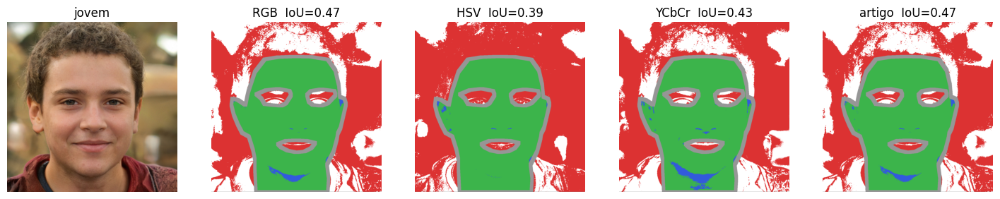


jovem_tinta  (faixa de borda = 6px, ignora 24% da imagem)
  RGB     prec=0.687 rec=0.954 IoU=0.665 F1=0.799  (marca 50% da imagem)
  HSV     prec=0.622 rec=0.956 IoU=0.605 F1=0.754  (marca 52% da imagem)
  YCbCr   prec=0.650 rec=0.884 IoU=0.599 F1=0.749  (marca 47% da imagem)
  artigo  prec=0.693 rec=0.945 IoU=0.666 F1=0.799  (marca 48% da imagem)


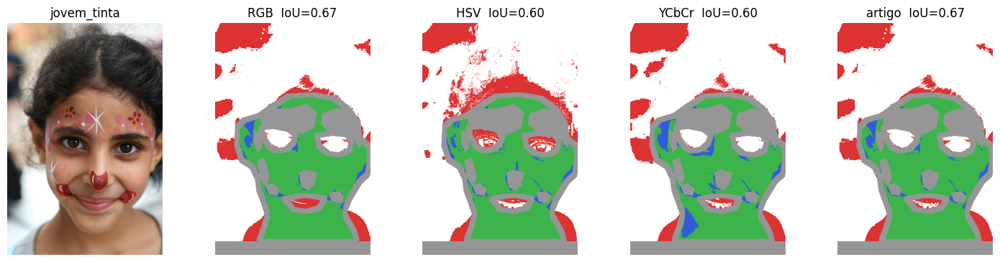


mulher  (faixa de borda = 8px, ignora 23% da imagem)
  RGB     prec=0.936 rec=0.780 IoU=0.741 F1=0.851  (marca 34% da imagem)
  HSV     prec=0.817 rec=0.907 IoU=0.754 F1=0.860  (marca 45% da imagem)
  YCbCr   prec=0.941 rec=0.700 IoU=0.671 F1=0.803  (marca 31% da imagem)
  artigo  prec=0.941 rec=0.777 IoU=0.741 F1=0.851  (marca 34% da imagem)


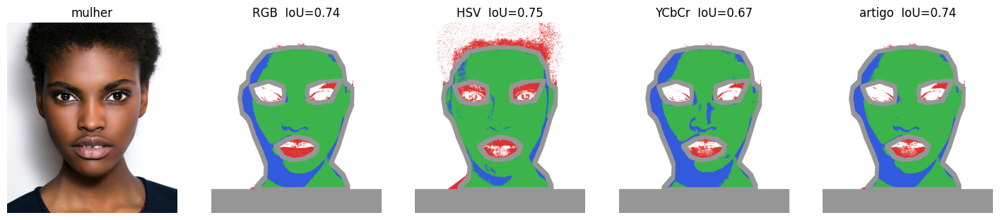


homem  (faixa de borda = 10px, ignora 9% da imagem)
  RGB     prec=0.949 rec=0.920 IoU=0.877 F1=0.934  (marca 38% da imagem)
  HSV     prec=0.771 rec=0.981 IoU=0.760 F1=0.863  (marca 50% da imagem)
  YCbCr   prec=0.877 rec=0.880 IoU=0.784 F1=0.879  (marca 39% da imagem)
  artigo  prec=0.951 rec=0.920 IoU=0.878 F1=0.935  (marca 38% da imagem)


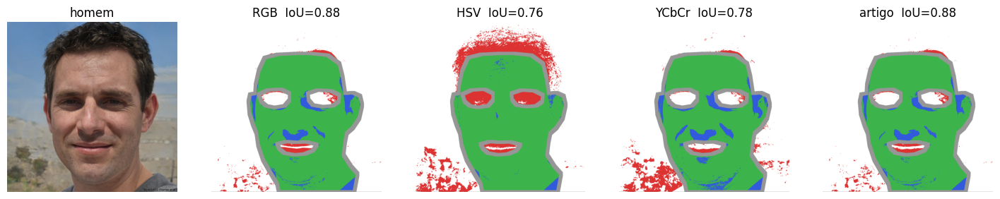

In [42]:
RESULTADOS = {}
for nome, img in IMGS.items():
    ref = MASCARAS[nome]
    faixa, raio = faixa_borda(ref)
    faixa |= regiao_ignorada(ref.shape, REFERENCIA[nome])
    print(f"\n{nome}  (faixa de borda = {raio}px, ignora {faixa.mean()*100:.0f}% da imagem)")
    fig, ax = plt.subplots(1, 5, figsize=(18, 4.2))
    ax[0].imshow(img); ax[0].set_title(nome); ax[0].axis('off')
    for a, (rn, regra) in zip(ax[1:], REGRAS.items()):
        pred = regra(img)
        mt = metricas(pred, ref, faixa)
        RESULTADOS[(nome, rn)] = mt
        print(f"  {rn:7s} prec={mt['prec']:.3f} rec={mt['rec']:.3f} IoU={mt['iou']:.3f} F1={mt['f1']:.3f}  (marca {mt['pele_pred']*100:.0f}% da imagem)")
        a.imshow(mapa_erro(pred, ref, faixa)); a.set_title(f"{rn}  IoU={mt['iou']:.2f}"); a.axis('off')
    plt.show()

define a regra HSV v2 (a do artigo com um limite mínimo de brilho V), a região válida de cada face (tudo menos a faixa de borda e a região ignorada) e a função que avalia uma regra nas quatro imagens.


In [43]:
def regra_hsv_v2(img, v_min=0.0, s_min=0.23, s_max=0.68, h_max=50):
    H, S, V = rgb_para_hsv(img)
    return (H <= h_max) & (S >= s_min) & (S <= s_max) & (V >= v_min)

VALIDO = {}
for nome in IMGS:
    faixa, _ = faixa_borda(MASCARAS[nome])
    VALIDO[nome] = ~(faixa | regiao_ignorada(MASCARAS[nome].shape, REFERENCIA[nome]))

def avaliar(regra, rotulo, **params):
    """Aplica a regra nas 4 imagens; imprime IoU por imagem, média e recall da mulher."""
    res = {nome: metricas(regra(img, **params), MASCARAS[nome], ~VALIDO[nome]) for nome, img in IMGS.items()}
    ious = [r['iou'] for r in res.values()]
    print(f"{rotulo:20s}", "  ".join(f"{n}={r['iou']:.3f}" for n, r in res.items()),
          f"| média={np.mean(ious):.3f} | recall mulher={res['mulher']['rec']:.3f}")
    return res

pele (referência)        mediana de V = 0.569
falso positivo HSV       mediana de V = 0.165
pele perdida pelo RGB    mediana de V = 0.239


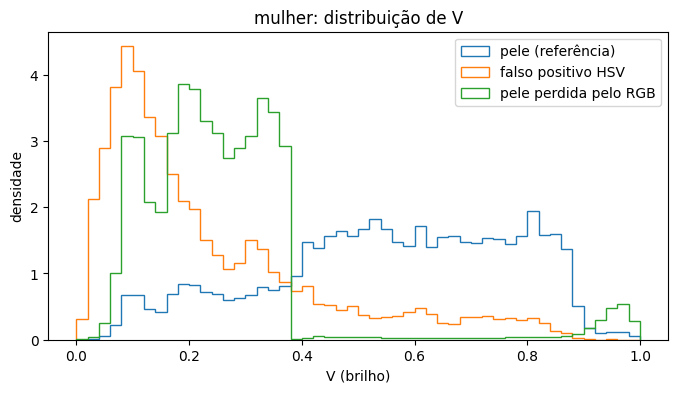

In [44]:
H, S, V = rgb_para_hsv(IMGS['mulher'])
ref, val = MASCARAS['mulher'], VALIDO['mulher']
fp_hsv = regra_hsv(IMGS['mulher']) & ~ref & val          # o que o HSV marca a mais (cabelo)
fn_rgb = ~regra_rgb(IMGS['mulher']) & ref & val          # pele que o RGB perde (sombra)
plt.figure(figsize=(8, 4))
for m, rot in [(ref & val, 'pele (referência)'), (fp_hsv, 'falso positivo HSV'), (fn_rgb, 'pele perdida pelo RGB')]:
    plt.hist(V[m], bins=50, range=(0, 1), histtype='step', density=True, lw=2, label=rot)
    print(f"{rot:24s} mediana de V = {np.median(V[m]):.3f}")
plt.xlabel('V (brilho)'); plt.ylabel('densidade'); plt.legend(); plt.title('mulher: distribuição de V')
plt.show()

H1: v_min
RGB (referência)     jovem=0.467  jovem_tinta=0.665  mulher=0.741  homem=0.877 | média=0.687 | recall mulher=0.780
HSV v_min=0.0        jovem=0.387  jovem_tinta=0.605  mulher=0.754  homem=0.760 | média=0.626 | recall mulher=0.907
HSV v_min=0.1        jovem=0.387  jovem_tinta=0.622  mulher=0.787  homem=0.772 | média=0.642 | recall mulher=0.904
HSV v_min=0.2        jovem=0.392  jovem_tinta=0.667  mulher=0.800  homem=0.825 | média=0.671 | recall mulher=0.869
HSV v_min=0.3        jovem=0.413  jovem_tinta=0.701  mulher=0.764  homem=0.848 | média=0.681 | recall mulher=0.809
HSV v_min=0.4        jovem=0.446  jovem_tinta=0.714  mulher=0.709  homem=0.815 | média=0.671 | recall mulher=0.734
HSV v_min=0.5        jovem=0.507  jovem_tinta=0.639  mulher=0.575  homem=0.600 | média=0.580 | recall mulher=0.589


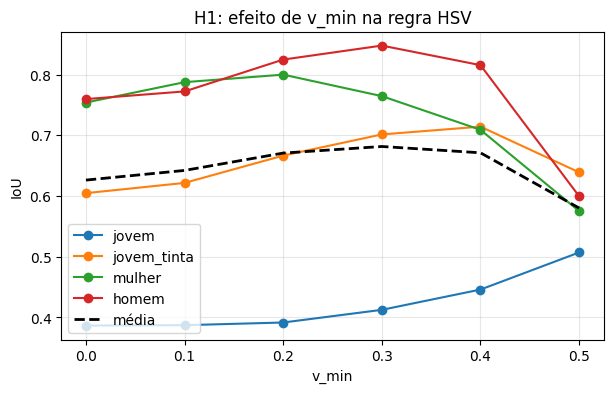

In [45]:
print("H1: v_min")
avaliar(lambda img: regra_rgb(img), "RGB (referência)")
H1 = {}
for v in [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]:
    H1[v] = avaliar(regra_hsv_v2, f"HSV v_min={v}", v_min=v)

nomes = list(IMGS)
plt.figure(figsize=(7, 4))
for nome in nomes:
    plt.plot(list(H1), [H1[v][nome]['iou'] for v in H1], 'o-', label=nome)
plt.plot(list(H1), [np.mean([H1[v][n]['iou'] for n in nomes]) for v in H1], 'k--', lw=2, label='média')
plt.xlabel('v_min'); plt.ylabel('IoU'); plt.legend(); plt.title('H1: efeito de v_min na regra HSV'); plt.grid(alpha=.3)
plt.show()

pele (referência)        mediana de S = 0.441
falso positivo (fundo)   mediana de S = 0.449


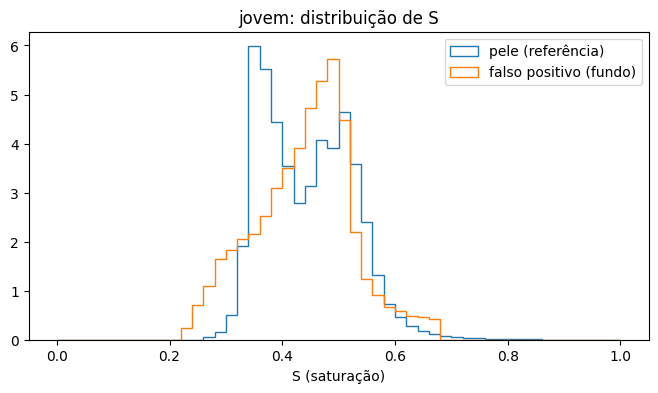

H2: s_min (com v_min=0.2)
HSV s_min=0.23       jovem=0.392  jovem_tinta=0.667  mulher=0.800  homem=0.825 | média=0.671 | recall mulher=0.869
HSV s_min=0.28       jovem=0.401  jovem_tinta=0.684  mulher=0.783  homem=0.821 | média=0.672 | recall mulher=0.847
HSV s_min=0.33       jovem=0.415  jovem_tinta=0.667  mulher=0.734  homem=0.636 | média=0.613 | recall mulher=0.790
HSV s_min=0.38       jovem=0.329  jovem_tinta=0.619  mulher=0.676  homem=0.265 | média=0.472 | recall mulher=0.721


In [46]:
V_MIN = 0.2   # <- valor escolhido pelo critério definido antes

H, S, V = rgb_para_hsv(IMGS['jovem'])
ref, val = MASCARAS['jovem'], VALIDO['jovem']
fp = regra_hsv_v2(IMGS['jovem'], v_min=V_MIN) & ~ref & val     # fundo bege marcado como pele
plt.figure(figsize=(8, 4))
for m, rot in [(ref & val, 'pele (referência)'), (fp, 'falso positivo (fundo)')]:
    plt.hist(S[m], bins=50, range=(0, 1), histtype='step', density=True, lw=2, label=rot)
    print(f"{rot:24s} mediana de S = {np.median(S[m]):.3f}")
plt.xlabel('S (saturação)'); plt.legend(); plt.title('jovem: distribuição de S'); plt.show()

print(f"H2: s_min (com v_min={V_MIN})")
H2 = {}
for s in [0.23, 0.28, 0.33, 0.38]:
    H2[s] = avaliar(regra_hsv_v2, f"HSV s_min={s}", v_min=V_MIN, s_min=s)

Hipótese 3 da etapa 1. Testa a interseção das regras HSV v2 e RGB (o pixel precisa passar nas duas).
a média sobe, mas o recall da mulher cai (perde a pele em sombra recuperada pelo HSV v2), então não foi adotada.

H3: interseção
RGB                  jovem=0.467  jovem_tinta=0.665  mulher=0.741  homem=0.877 | média=0.687 | recall mulher=0.780
HSV v2               jovem=0.392  jovem_tinta=0.667  mulher=0.800  homem=0.825 | média=0.671 | recall mulher=0.869
HSV v2 ∧ RGB         jovem=0.473  jovem_tinta=0.715  mulher=0.727  homem=0.881 | média=0.699 | recall mulher=0.756
   jovem        precisão=0.479 recall=0.974
   jovem_tinta  precisão=0.752 recall=0.937
   mulher       precisão=0.950 recall=0.756
   homem        precisão=0.958 recall=0.916


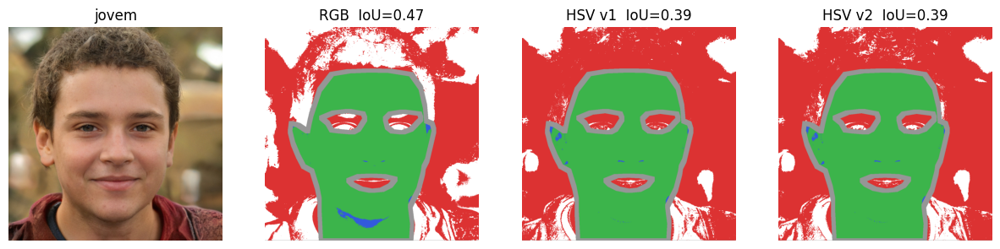

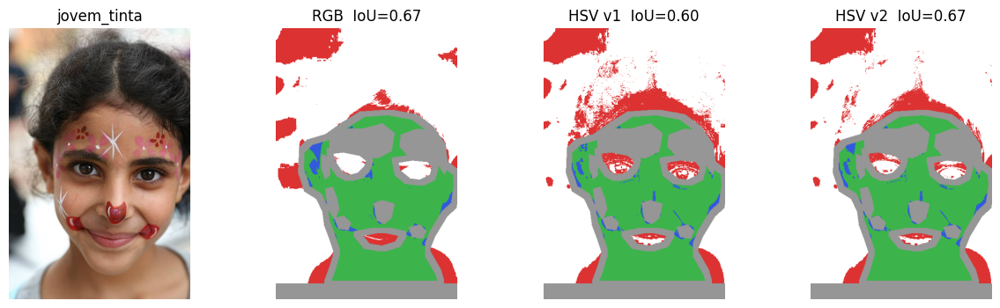

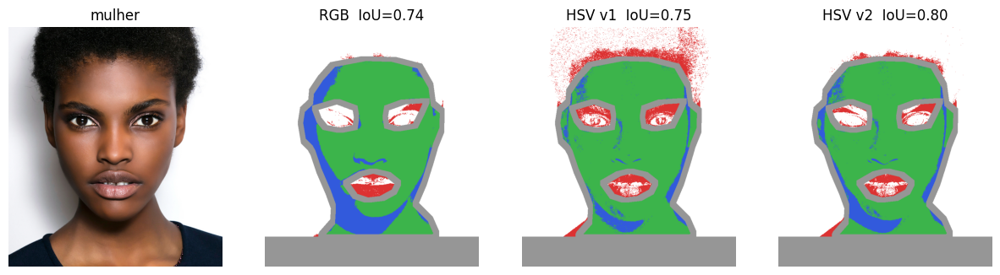

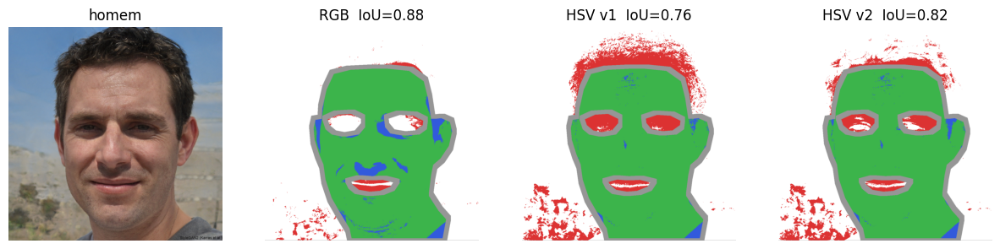

In [47]:
S_MIN = 0.23  # <- valor escolhido no passo 3

def regra_hsv_e_rgb(img, v_min=V_MIN, s_min=S_MIN):
    return regra_hsv_v2(img, v_min=v_min, s_min=s_min) & regra_rgb(img)

print("H3: interseção")
avaliar(lambda img: regra_rgb(img), "RGB")
avaliar(regra_hsv_v2, "HSV v2", v_min=V_MIN, s_min=S_MIN)
H3 = avaliar(regra_hsv_e_rgb, "HSV v2 ∧ RGB")
for nome, r in H3.items():
    print(f"   {nome:12s} precisão={r['prec']:.3f} recall={r['rec']:.3f}")


VERSOES = {'RGB': regra_rgb,
           'HSV v1': regra_hsv,
           'HSV v2': lambda img: regra_hsv_v2(img, v_min=V_MIN, s_min=S_MIN)}
for nome, img in IMGS.items():
    fig, ax = plt.subplots(1, 4, figsize=(15, 4))
    ax[0].imshow(img); ax[0].set_title(nome); ax[0].axis('off')
    for a, (rot, regra) in zip(ax[1:], VERSOES.items()):
        pred = regra(img)
        mt = metricas(pred, MASCARAS[nome], ~VALIDO[nome])
        a.imshow(mapa_erro(pred, MASCARAS[nome], ~VALIDO[nome]))
        a.set_title(f"{rot}  IoU={mt['iou']:.2f}"); a.axis('off')
    plt.show()

# Testes de brilho

Hipótese 4 (teste de brilho). Multiplica os três canais das imagens por fatores de 0,5 a 1,6 e mede o IoU de cada regra; calcula a queda máxima em relação à imagem original.
testar a robustez à luz. Escurecer multiplica R, G e B pelo mesmo fator: H e S não mudam, mas os limites fixos do RGB (R > 95) deixam de valer. Queda máxima média: RGB 0,488, HSV v2 0,113.

IoU médio (4 imagens)
fator         RGB   HSV v1   HSV v2
0.5         0.230    0.626    0.670
0.7         0.556    0.626    0.679
0.85        0.657    0.626    0.675
1.0         0.687    0.626    0.671
1.15        0.683    0.625    0.665
1.3         0.679    0.620    0.652
1.6         0.591    0.538    0.558

Queda máxima de IoU em relação ao original (quanto menor, mais estável)
  RGB     jovem=0.186  jovem_tinta=0.432  mulher=0.530  homem=0.803 | média=0.488
  HSV v1  jovem=0.115  jovem_tinta=0.053  mulher=0.087  homem=0.096 | média=0.088
  HSV v2  jovem=0.119  jovem_tinta=0.092  mulher=0.099  homem=0.139 | média=0.113


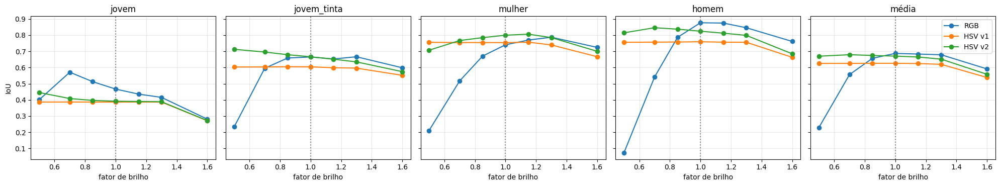

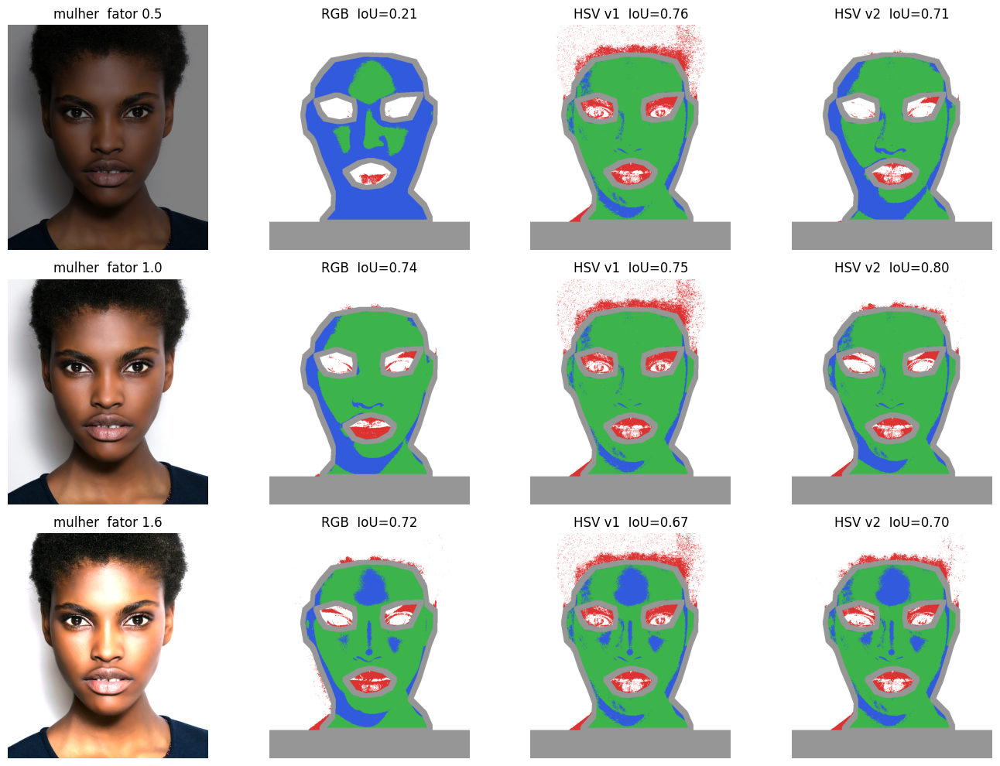

In [48]:
FATORES = [0.5, 0.7, 0.85, 1.0, 1.15, 1.3, 1.6]
REGRAS_BRILHO = {'RGB':   regra_rgb,
                 'HSV v1': regra_hsv,
                 'HSV v2': lambda img: regra_hsv_v2(img, v_min=V_MIN, s_min=S_MIN)}

def ajustar_brilho(img, fator):
    """Multiplica os 3 canais pelo mesmo fator (simula mais/menos luz) e limita a 0–255."""
    return np.clip(img.astype(np.float64) * fator, 0, 255).astype(np.uint8)

BRILHO = {}   # BRILHO[(nome, regra, fator)] = métricas
for nome, img in IMGS.items():
    for fator in FATORES:
        img_f = ajustar_brilho(img, fator)
        for rot, regra in REGRAS_BRILHO.items():
            BRILHO[(nome, rot, fator)] = metricas(regra(img_f), MASCARAS[nome], ~VALIDO[nome])

# tabela: IoU médio das 4 imagens por fator
print("IoU médio (4 imagens)")
print(f"{'fator':8s}" + "".join(f"{rot:>9s}" for rot in REGRAS_BRILHO))
for fator in FATORES:
    print(f"{fator:<8}" + "".join(f"{np.mean([BRILHO[(n, rot, fator)]['iou'] for n in IMGS]):9.3f}" for rot in REGRAS_BRILHO))

# estabilidade: queda máxima de IoU em relação à imagem original (fator 1.0)
print("\nQueda máxima de IoU em relação ao original (quanto menor, mais estável)")
for rot in REGRAS_BRILHO:
    quedas = [BRILHO[(n, rot, 1.0)]['iou'] - min(BRILHO[(n, rot, f)]['iou'] for f in FATORES) for n in IMGS]
    print(f"  {rot:7s} " + "  ".join(f"{n}={q:.3f}" for n, q in zip(IMGS, quedas)) + f" | média={np.mean(quedas):.3f}")

# gráfico: uma curva por regra, um painel por imagem + média
nomes = list(IMGS)
fig, ax = plt.subplots(1, len(nomes) + 1, figsize=(4 * (len(nomes) + 1), 3.8), sharey=True)
for a, nome in zip(ax, nomes):
    for rot in REGRAS_BRILHO:
        a.plot(FATORES, [BRILHO[(nome, rot, f)]['iou'] for f in FATORES], 'o-', label=rot)
    a.axvline(1.0, color='gray', ls=':'); a.set_title(nome); a.set_xlabel('fator de brilho'); a.grid(alpha=.3)
for rot in REGRAS_BRILHO:
    ax[-1].plot(FATORES, [np.mean([BRILHO[(n, rot, f)]['iou'] for n in nomes]) for f in FATORES], 'o-', label=rot)
ax[-1].axvline(1.0, color='gray', ls=':'); ax[-1].set_title('média'); ax[-1].set_xlabel('fator de brilho'); ax[-1].grid(alpha=.3)
ax[0].set_ylabel('IoU'); ax[-1].legend()
plt.tight_layout(); plt.show()

# exemplo visual: mulher escurecida, original e clareada
nome = 'mulher'
fig, ax = plt.subplots(3, 4, figsize=(14, 10))
for linha, fator in enumerate([0.5, 1.0, 1.6]):
    img_f = ajustar_brilho(IMGS[nome], fator)
    ax[linha, 0].imshow(img_f); ax[linha, 0].set_title(f"{nome}  fator {fator}"); ax[linha, 0].axis('off')
    for a, (rot, regra) in zip(ax[linha, 1:], REGRAS_BRILHO.items()):
        pred = regra(img_f)
        a.imshow(mapa_erro(pred, MASCARAS[nome], ~VALIDO[nome]))
        a.set_title(f"{rot}  IoU={BRILHO[(nome, rot, fator)]['iou']:.2f}"); a.axis('off')
plt.tight_layout(); plt.show()

# Projeto 2, etapa de segmentação por semente

Semente

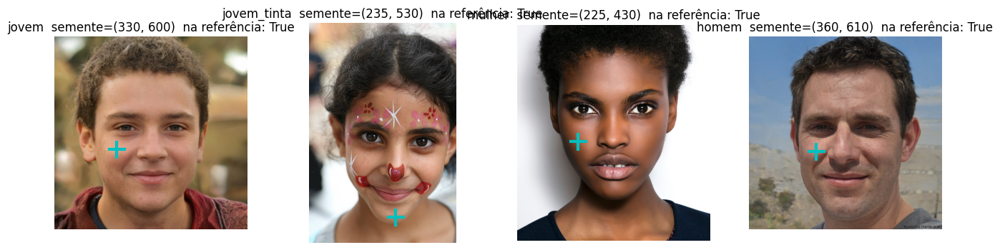

In [49]:
SEMENTES = {'jovem': (330, 600), 'jovem_tinta': (235, 530), 'mulher': (225, 430), 'homem': (360, 610)}

fig, ax = plt.subplots(1, len(IMGS), figsize=(4 * len(IMGS), 4))
for a, (nome, img) in zip(ax, IMGS.items()):
    a.imshow(img); a.plot(*SEMENTES[nome], 'c+', ms=18, mew=3)
    a.set_title(f"{nome}  semente={SEMENTES[nome]}  na referência: {MASCARAS[nome][SEMENTES[nome][1], SEMENTES[nome][0]]}")
    a.axis('off')
plt.show()

Algoritmo


In [50]:
def cor_da_semente(img, semente, janela=5):
    """Cor de partida = média de uma janela janela×janela em volta da semente (menos sensível a ruído que 1 pixel)."""
    x, y = semente; r = janela // 2
    return img[y - r:y + r + 1, x - r:x + r + 1].reshape(-1, 3).astype(np.float64).mean(axis=0)

print("Variação da cor da pele em relação à semente (maior |Δ| entre os canais R, G, B)")
for nome, img in IMGS.items():
    x, y = SEMENTES[nome]
    pele = img[MASCARAS[nome] & VALIDO[nome]].astype(np.float64)
    dif = np.abs(pele - cor_da_semente(img, SEMENTES[nome])).max(axis=1)
    janela = img[y - 2:y + 3, x - 2:x + 3].reshape(-1, 3).astype(np.float64)
    print(f"  {nome:12s} desvio da pele (R,G,B)={pele.std(axis=0).round(1)}  "
          f"mediana |Δ|={np.median(dif):.0f}  75%={np.percentile(dif, 75):.0f}  "
          f"desvio na janela 5x5={janela.std(axis=0).round(1)}")

def crescimento_regiao(img, semente, tolerancia, media_atualizada=True, janela=5):
    """Busca em largura a partir da semente (vizinhança 4).
    Um pixel entra na região se |pixel - média| < tolerância em CADA canal (R, G e B).
    media_atualizada=True: a média é recalculada a cada pixel aceito (como no código do professor).
    media_atualizada=False: compara sempre com a cor da semente."""
    h, w = img.shape[:2]
    dados = img.astype(np.float64)
    regiao = np.zeros((h, w), dtype=bool)
    visitado = np.zeros((h, w), dtype=bool)
    soma = cor_da_semente(img, semente, janela)
    n = 1
    x0, y0 = semente
    fila = deque([(y0, x0)])
    visitado[y0, x0] = True
    while fila:
        y, x = fila.popleft()
        media = soma / n
        if np.all(np.abs(dados[y, x] - media) < tolerancia):
            regiao[y, x] = True
            if media_atualizada:
                soma += dados[y, x]; n += 1
            for ny, nx in ((y + 1, x), (y - 1, x), (y, x - 1), (y, x + 1)):
                if 0 <= ny < h and 0 <= nx < w and not visitado[ny, nx]:
                    visitado[ny, nx] = True
                    fila.append((ny, nx))
    return regiao

Variação da cor da pele em relação à semente (maior |Δ| entre os canais R, G, B)
  jovem        desvio da pele (R,G,B)=[33.  30.3 29.8]  mediana |Δ|=47  75%=74  desvio na janela 5x5=[1.7 1.8 1.8]
  jovem_tinta  desvio da pele (R,G,B)=[38.2 35.9 34.7]  mediana |Δ|=29  75%=50  desvio na janela 5x5=[2.7 2.2 2.4]
  mulher       desvio da pele (R,G,B)=[55.1 42.5 41.5]  mediana |Δ|=45  75%=72  desvio na janela 5x5=[5.9 5.  4.4]
  homem        desvio da pele (R,G,B)=[35.3 28.6 26.3]  mediana |Δ|=49  75%=76  desvio na janela 5x5=[2.1 2.9 3.5]


Varredura de tolerância


média atualizada
  tol= 20  jovem=0.368 (p=1.00 r=0.37)  jovem_tinta=0.068 (p=1.00 r=0.07)  mulher=0.069 (p=1.00 r=0.07)  homem=0.053 (p=1.00 r=0.05)  | média=0.139
  tol= 30  jovem=0.469 (p=0.99 r=0.47)  jovem_tinta=0.496 (p=0.94 r=0.51)  mulher=0.255 (p=0.98 r=0.26)  homem=0.127 (p=1.00 r=0.13)  | média=0.337
  tol= 40  jovem=0.499 (p=0.81 r=0.57)  jovem_tinta=0.601 (p=0.88 r=0.66)  mulher=0.406 (p=0.96 r=0.41)  homem=0.437 (p=1.00 r=0.44)  | média=0.486
  tol= 50  jovem=0.488 (p=0.53 r=0.87)  jovem_tinta=0.687 (p=0.86 r=0.77)  mulher=0.553 (p=0.95 r=0.57)  homem=0.535 (p=0.60 r=0.82)  | média=0.566
  tol= 60  jovem=0.453 (p=0.47 r=0.93)  jovem_tinta=0.766 (p=0.85 r=0.88)  mulher=0.666 (p=0.95 r=0.69)  homem=0.557 (p=0.59 r=0.92)  | média=0.610

média fixa
  tol= 20  jovem=0.032 (p=1.00 r=0.03)  jovem_tinta=0.067 (p=1.00 r=0.07)  mulher=0.068 (p=1.00 r=0.07)  homem=0.052 (p=1.00 r=0.05)  | média=0.055
  tol= 30  jovem=0.336 (p=1.00 r=0.34)  jovem_tinta=0.486 (p=0.94 r=0.50)  mulher=

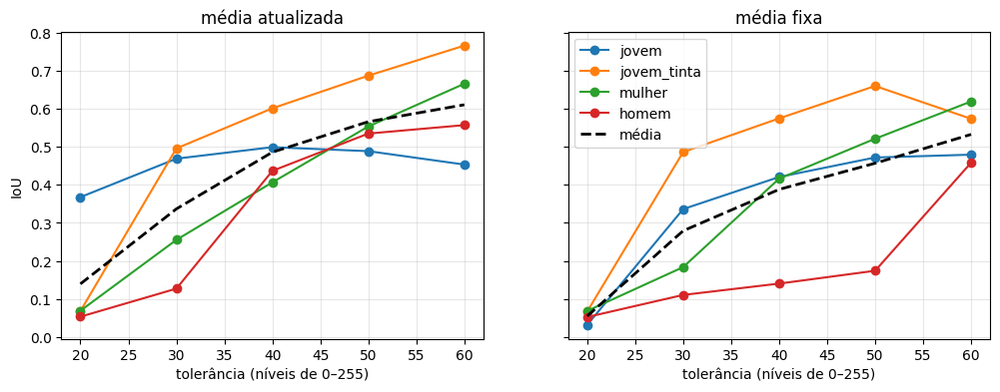

In [51]:
TOLERANCIAS = [20, 30, 40, 50, 60]
SEED = {}   # SEED[(nome, variante, tol)] = métricas
for media_atualizada, variante in [(True, 'média atualizada'), (False, 'média fixa')]:
    print(f"\n{variante}")
    for tol in TOLERANCIAS:
        linha = []
        for nome, img in IMGS.items():
            reg = crescimento_regiao(img, SEMENTES[nome], tol, media_atualizada)
            mt = metricas(reg, MASCARAS[nome], ~VALIDO[nome])
            SEED[(nome, variante, tol)] = mt
            linha.append(f"{nome}={mt['iou']:.3f} (p={mt['prec']:.2f} r={mt['rec']:.2f})")
        media = np.mean([SEED[(n, variante, tol)]['iou'] for n in IMGS])
        print(f"  tol={tol:3d}  " + "  ".join(linha) + f"  | média={media:.3f}")

nomes = list(IMGS)
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for a, variante in zip(ax, ['média atualizada', 'média fixa']):
    for nome in nomes:
        a.plot(TOLERANCIAS, [SEED[(nome, variante, t)]['iou'] for t in TOLERANCIAS], 'o-', label=nome)
    a.plot(TOLERANCIAS, [np.mean([SEED[(n, variante, t)]['iou'] for n in nomes]) for t in TOLERANCIAS], 'k--', lw=2, label='média')
    a.set_title(variante); a.set_xlabel('tolerância (níveis de 0–255)'); a.grid(alpha=.3)
ax[0].set_ylabel('IoU'); ax[1].legend(); plt.show()

Mapas de erro e resultados

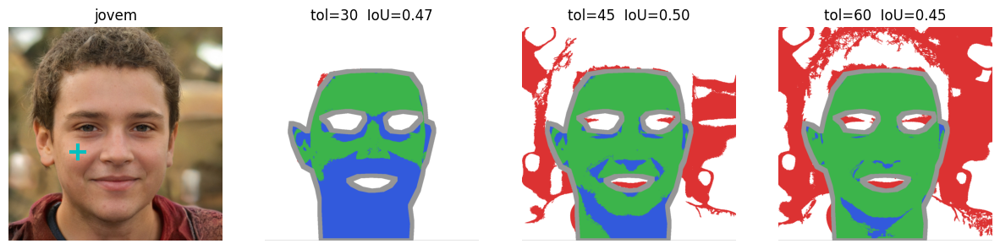

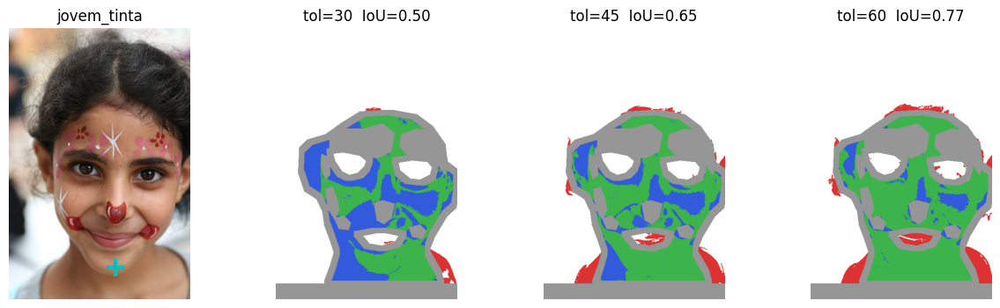

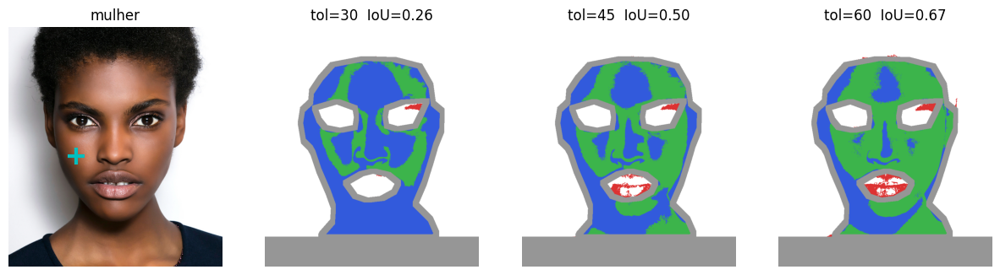

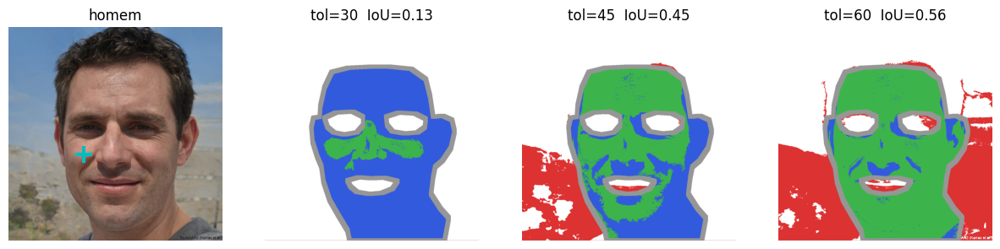

In [52]:
for nome, img in IMGS.items():
    fig, ax = plt.subplots(1, 4, figsize=(15, 4))
    ax[0].imshow(img); ax[0].plot(*SEMENTES[nome], 'c+', ms=14, mew=3); ax[0].set_title(nome); ax[0].axis('off')
    for a, tol in zip(ax[1:], [30, 45, 60]):
        reg = crescimento_regiao(img, SEMENTES[nome], tol, True)
        mt = metricas(reg, MASCARAS[nome], ~VALIDO[nome])
        a.imshow(mapa_erro(reg, MASCARAS[nome], ~VALIDO[nome])); a.set_title(f"tol={tol}  IoU={mt['iou']:.2f}"); a.axis('off')
    plt.show()

# H1:
mede, para cada face, a matiz e a saturação da semente e quanto da pele está a menos de 10° de matiz e 0,2 de saturação dela; mede também a matiz do fundo que vazou na versão 1.
evidência para a Hipótese 1 da etapa 2. 94% a 99% da pele está a menos de 10° da semente, e o fundo da jovem tem matiz 36° contra 21° da pele: separável por matiz.

Mede dispersão em relação a semente e matriz do fundo

In [53]:
for nome, img in IMGS.items():
    H, S, V = rgb_para_hsv(img)
    x, y = SEMENTES[nome]
    h0 = np.median(H[y - 2:y + 3, x - 2:x + 3]); s0 = np.median(S[y - 2:y + 3, x - 2:x + 3])
    pele = MASCARAS[nome] & VALIDO[nome]
    dH = np.abs(H[pele] - h0); dH = np.minimum(dH, 360 - dH)
    vazou = crescimento_regiao(img, SEMENTES[nome], 60, True) & ~MASCARAS[nome] & VALIDO[nome]
    linha = (f"  {nome:12s} semente H={h0:.1f}° S={s0:.2f} | pele: H mediana={np.median(H[pele]):.1f}°  "
             f"|ΔH|<10°: {(dH < 10).mean()*100:.0f}%  |ΔS|<0,2: {(np.abs(S[pele] - s0) < 0.2).mean()*100:.0f}%")
    if vazou.sum() > 0:
        linha += f" | fundo que vazou na v1: H mediana={np.median(H[vazou]):.1f}°  S mediana={np.median(S[vazou]):.2f}"
    print(linha)

  jovem        semente H=16.6° S=0.34 | pele: H mediana=20.8°  |ΔH|<10°: 99%  |ΔS|<0,2: 88% | fundo que vazou na v1: H mediana=36.3°  S mediana=0.44
  jovem_tinta  semente H=21.4° S=0.41 | pele: H mediana=21.4°  |ΔH|<10°: 96%  |ΔS|<0,2: 92% | fundo que vazou na v1: H mediana=23.2°  S mediana=0.39
  mulher       semente H=18.9° S=0.59 | pele: H mediana=18.3°  |ΔH|<10°: 94%  |ΔS|<0,2: 77% | fundo que vazou na v1: H mediana=10.5°  S mediana=0.43
  homem        semente H=15.0° S=0.36 | pele: H mediana=16.9°  |ΔH|<10°: 97%  |ΔS|<0,2: 98% | fundo que vazou na v1: H mediana=42.9°  S mediana=0.13


Hipótese 1 da etapa 2. Novo critério: o pixel entra se a matiz está a menos de tol_H da semente E a saturação a menos de tol_S E o brilho V ≥ 0,2 (as três condições ao mesmo tempo). Depois só entram os pixels conectados à semente. Testa uma grade de tolerâncias e mostra mapas de calor.
matiz e saturação não mudam com a sombra, e a comparação é com a cor da própria pessoa (referência local). Escolha pelo critério definido antes: maior IoU médio sem nenhuma imagem com precisão abaixo de 0,8 → 10° e 0,20.

H1 tol_H= 5 tol_S=0.10      jovem=0.127(p=1.00 r=0.13)  jovem_tinta=0.446(p=0.85 r=0.48)  mulher=0.482(p=0.99 r=0.48)  homem=0.696(p=0.95 r=0.72)  | média=0.438  prec mín=0.85
H1 tol_H= 5 tol_S=0.15      jovem=0.348(p=1.00 r=0.35)  jovem_tinta=0.649(p=0.86 r=0.72)  mulher=0.589(p=0.97 r=0.60)  homem=0.735(p=0.94 r=0.77)  | média=0.580  prec mín=0.86
H1 tol_H= 5 tol_S=0.20      jovem=0.394(p=1.00 r=0.39)  jovem_tinta=0.739(p=0.86 r=0.84)  mulher=0.654(p=0.97 r=0.67)  homem=0.741(p=0.94 r=0.78)  | média=0.632  prec mín=0.86
H1 tol_H= 5 tol_S=0.25      jovem=0.410(p=0.95 r=0.42)  jovem_tinta=0.760(p=0.85 r=0.88)  mulher=0.695(p=0.97 r=0.71)  homem=0.742(p=0.94 r=0.78)  | média=0.652  prec mín=0.85
H1 tol_H=10 tol_S=0.10      jovem=0.421(p=0.99 r=0.42)  jovem_tinta=0.460(p=0.81 r=0.52)  mulher=0.497(p=0.98 r=0.50)  homem=0.850(p=0.94 r=0.90)  | média=0.557  prec mín=0.81
H1 tol_H=10 tol_S=0.15      jovem=0.559(p=0.96 r=0.57)  jovem_tinta=0.675(p=0.83 r=0.79)  mulher=0.606(p=0.96 r=0.62)  h

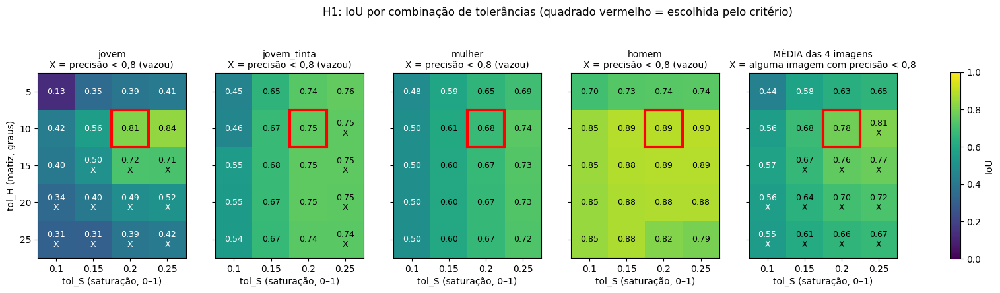

In [54]:
def crescer_em_mascara(permitido, semente):
    """Região = pixels de `permitido` conectados à semente (vizinhança 4, busca em largura)."""
    h, w = permitido.shape
    regiao = np.zeros((h, w), dtype=bool)
    x0, y0 = semente
    if not permitido[y0, x0]:
        return regiao
    fila = deque([(y0, x0)]); regiao[y0, x0] = True
    while fila:
        y, x = fila.popleft()
        for ny, nx in ((y + 1, x), (y - 1, x), (y, x - 1), (y, x + 1)):
            if 0 <= ny < h and 0 <= nx < w and permitido[ny, nx] and not regiao[ny, nx]:
                regiao[ny, nx] = True
                fila.append((ny, nx))
    return regiao

def criterio_hs(img, semente, tol_h, tol_s, v_min=V_MIN, janela=5):
    """Pixels cuja matiz e saturação estão próximas das da semente (e com V >= v_min).
    A diferença de matiz é circular: 359° e 1° estão a 2° de distância."""
    H, S, V = rgb_para_hsv(img)
    x, y = semente; r = janela // 2
    h0 = np.median(H[y - r:y + r + 1, x - r:x + r + 1])
    s0 = np.median(S[y - r:y + r + 1, x - r:x + r + 1])
    dH = np.abs(H - h0)
    dH = np.minimum(dH, 360 - dH)
    return (dH < tol_h) & (np.abs(S - s0) < tol_s) & (V >= v_min)

def avaliar_seg(funcao, rotulo):
    """funcao(nome, img) -> máscara. Imprime IoU, precisão e recall por imagem."""
    res = {n: metricas(funcao(n, img), MASCARAS[n], ~VALIDO[n]) for n, img in IMGS.items()}
    print(f"{rotulo:28s}" + "  ".join(f"{n}={r['iou']:.3f}(p={r['prec']:.2f} r={r['rec']:.2f})" for n, r in res.items())
          + f"  | média={np.mean([r['iou'] for r in res.values()]):.3f}  prec mín={min(r['prec'] for r in res.values()):.2f}")
    return res

TOL_H = [5, 10, 15, 20, 25]          # graus
TOL_S = [0.10, 0.15, 0.20, 0.25]     # escala 0–1
H1S = {}
for th in TOL_H:
    for ts in TOL_S:
        H1S[(th, ts)] = avaliar_seg(lambda n, img: crescer_em_mascara(criterio_hs(img, SEMENTES[n], th, ts), SEMENTES[n]),
                                    f"H1 tol_H={th:2d} tol_S={ts:.2f}")
validos = [k for k in H1S if min(H1S[k][n]['prec'] for n in IMGS) >= 0.8]
TOL_H_ESC, TOL_S_ESC = max(validos, key=lambda k: np.mean([H1S[k][n]['iou'] for n in IMGS]))
print(f"\nEscolhido pelo critério: tol_H={TOL_H_ESC}, tol_S={TOL_S_ESC}")

# ---------- Mapas de calor: um por imagem + média ----------
nomes = list(IMGS)
paineis = nomes + ['média']
fig, ax = plt.subplots(1, len(paineis), figsize=(4.2 * len(paineis), 4.6), sharey=True)
for a, painel in zip(ax, paineis):
    if painel == 'média':
        iou  = np.array([[np.mean([H1S[(th, ts)][n]['iou'] for n in nomes]) for ts in TOL_S] for th in TOL_H])
        ruim = np.array([[min(H1S[(th, ts)][n]['prec'] for n in nomes) < 0.8 for ts in TOL_S] for th in TOL_H])
        titulo = 'MÉDIA das 4 imagens\nX = alguma imagem com precisão < 0,8'
    else:
        iou  = np.array([[H1S[(th, ts)][painel]['iou'] for ts in TOL_S] for th in TOL_H])
        ruim = np.array([[H1S[(th, ts)][painel]['prec'] < 0.8 for ts in TOL_S] for th in TOL_H])
        titulo = f'{painel}\nX = precisão < 0,8 (vazou)'
    im = a.imshow(iou, cmap='viridis', vmin=0, vmax=1)
    for i in range(len(TOL_H)):
        for j in range(len(TOL_S)):
            a.text(j, i, f"{iou[i, j]:.2f}" + ("\nX" if ruim[i, j] else ""), ha='center', va='center',
                   fontsize=9, color='white' if iou[i, j] < 0.6 else 'black')
    if (TOL_H_ESC, TOL_S_ESC) in H1S:     # destaca a combinação escolhida
        i, j = TOL_H.index(TOL_H_ESC), TOL_S.index(TOL_S_ESC)
        a.add_patch(plt.Rectangle((j - .5, i - .5), 1, 1, fill=False, ec='red', lw=3))
    a.set_xticks(range(len(TOL_S))); a.set_xticklabels(TOL_S)
    a.set_yticks(range(len(TOL_H))); a.set_yticklabels(TOL_H)
    a.set_xlabel('tol_S (saturação, 0–1)'); a.set_title(titulo, fontsize=10)
ax[0].set_ylabel('tol_H (matiz, graus)')
fig.colorbar(im, ax=ax, shrink=0.8, label='IoU')
fig.suptitle('H1: IoU por combinação de tolerâncias (quadrado vermelho = escolhida pelo critério)', y=1.02)
plt.show()

H2 e comparação final

Comparação
v1 (RGB, tol=60)            jovem=0.453(p=0.47 r=0.93)  jovem_tinta=0.766(p=0.85 r=0.88)  mulher=0.666(p=0.95 r=0.69)  homem=0.557(p=0.59 r=0.92)  | média=0.610  prec mín=0.47
H1 (H,S)                    jovem=0.811(p=0.93 r=0.87)  jovem_tinta=0.754(p=0.83 r=0.90)  mulher=0.678(p=0.95 r=0.70)  homem=0.893(p=0.93 r=0.96)  | média=0.784  prec mín=0.83
H2 (H,S) ∧ máscara etapa 1  jovem=0.811(p=0.93 r=0.87)  jovem_tinta=0.753(p=0.83 r=0.89)  mulher=0.660(p=0.95 r=0.68)  homem=0.889(p=0.93 r=0.96)  | média=0.778  prec mín=0.83
etapa 1: HSV v2 (sem semente)jovem=0.392(p=0.39 r=0.99)  jovem_tinta=0.667(p=0.69 r=0.95)  mulher=0.800(p=0.91 r=0.87)  homem=0.825(p=0.84 r=0.98)  | média=0.671  prec mín=0.39


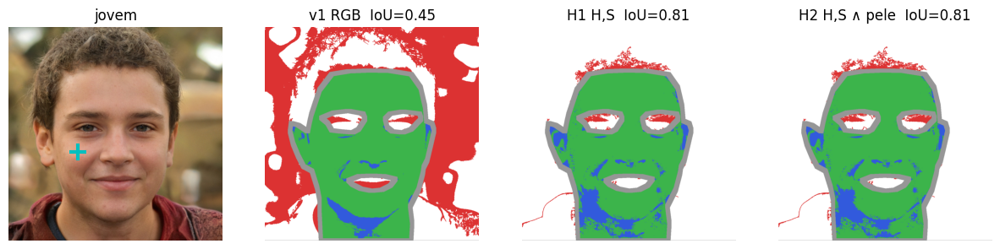

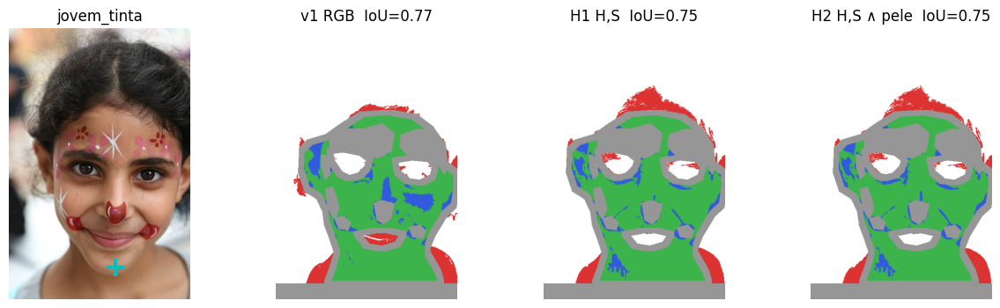

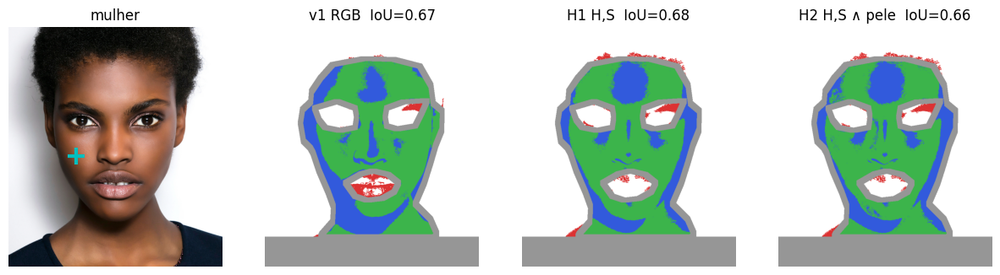

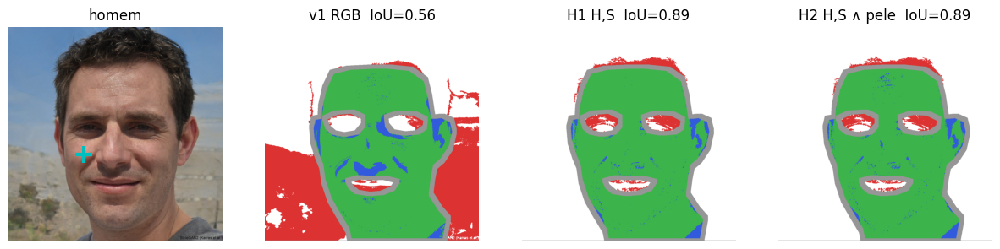

In [55]:
def seg_h1(n, img):
    return crescer_em_mascara(criterio_hs(img, SEMENTES[n], TOL_H_ESC, TOL_S_ESC), SEMENTES[n])

def seg_h2(n, img):
    pele_etapa1 = regra_hsv_v2(img, v_min=V_MIN, s_min=S_MIN)
    return crescer_em_mascara(criterio_hs(img, SEMENTES[n], TOL_H_ESC, TOL_S_ESC) & pele_etapa1, SEMENTES[n])

def seg_v1(n, img):
    return crescimento_regiao(img, SEMENTES[n], 60, True)

print("Comparação")
R_V1 = avaliar_seg(seg_v1, "v1 (RGB, tol=60)")
R_H1 = avaliar_seg(seg_h1, "H1 (H,S)")
R_H2 = avaliar_seg(seg_h2, "H2 (H,S) ∧ máscara etapa 1")
R_E1 = avaliar_seg(lambda n, img: regra_hsv_v2(img, v_min=V_MIN, s_min=S_MIN), "etapa 1: HSV v2 (sem semente)")

# mapas de erro lado a lado
VERSOES_SEG = {'v1 RGB': seg_v1, 'H1 H,S': seg_h1, 'H2 H,S ∧ pele': seg_h2}
for nome, img in IMGS.items():
    fig, ax = plt.subplots(1, 4, figsize=(15, 4))
    ax[0].imshow(img); ax[0].plot(*SEMENTES[nome], 'c+', ms=14, mew=3); ax[0].set_title(nome); ax[0].axis('off')
    for a, (rot, f) in zip(ax[1:], VERSOES_SEG.items()):
        reg = f(nome, img); mt = metricas(reg, MASCARAS[nome], ~VALIDO[nome])
        a.imshow(mapa_erro(reg, MASCARAS[nome], ~VALIDO[nome])); a.set_title(f"{rot}  IoU={mt['iou']:.2f}"); a.axis('off')
    plt.show()

# Aplicação da segunda etapa, Morfologia

In [56]:
def rotular(mascara):
    """Numera cada região conectada da máscara (vizinhança 4). Devolve (rotulos, quantidade)."""
    h, w = mascara.shape
    rotulos = np.zeros((h, w), dtype=np.int32)
    n = 0
    for y0, x0 in zip(*np.nonzero(mascara)):
        if rotulos[y0, x0]:
            continue                      # já pertence a uma região numerada
        n += 1
        rotulos[y0, x0] = n
        fila = deque([(y0, x0)])
        while fila:                       # mesma busca em largura do crescimento de região
            y, x = fila.popleft()
            for ny, nx in ((y + 1, x), (y - 1, x), (y, x - 1), (y, x + 1)):
                if 0 <= ny < h and 0 <= nx < w and mascara[ny, nx] and not rotulos[ny, nx]:
                    rotulos[ny, nx] = n
                    fila.append((ny, nx))
    return rotulos, n

In [57]:
def descrever(mascara):
    rot, n = rotular(mascara)
    areas = np.bincount(rot.ravel())[1:]          # área de cada região
    principal = rot == areas.argmax() + 1          # a maior região (o rosto)
    fragmentos = mascara & ~principal              # tudo que está fora dela

    rot_f, _ = rotular(~mascara)                   # regiões do "fundo"
    borda = np.unique(np.r_[rot_f[0], rot_f[-1], rot_f[:, 0], rot_f[:, -1]])
    buracos = ~mascara & ~np.isin(rot_f, borda)    # fundo que não toca a borda = buraco

    a_frag = np.delete(areas, areas.argmax())
    a_bur = np.bincount(rot_f[buracos])[1:]; a_bur = a_bur[a_bur > 0]
    return principal, fragmentos, buracos, a_frag, a_bur


jovem
  RGB      regiões= 865 | fragmentos= 864 (área típica 2 px, maior 2287 px) | buracos= 931 (área típica 3 px, maior 15931 px) | erro do fundo em fragmentos: 4%
  HSV v2   regiões= 601 | fragmentos= 600 (área típica 2 px, maior 3485 px) | buracos=1304 (área típica 2 px, maior 7147 px) | erro do fundo em fragmentos: 2%
  semente  regiões=   1 | fragmentos=   0 (área típica 0 px, maior 0 px) | buracos=1331 (área típica 2 px, maior 9675 px) | erro do fundo em fragmentos: 0%


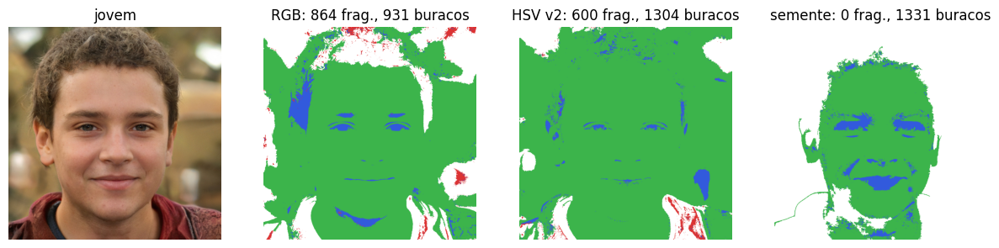


jovem_tinta
  RGB      regiões= 142 | fragmentos= 141 (área típica 1 px, maior 9351 px) | buracos= 256 (área típica 1 px, maior 3918 px) | erro do fundo em fragmentos: 55%
  HSV v2   regiões= 375 | fragmentos= 374 (área típica 1 px, maior 8193 px) | buracos= 445 (área típica 1 px, maior 1511 px) | erro do fundo em fragmentos: 47%
  semente  regiões=   1 | fragmentos=   0 (área típica 0 px, maior 0 px) | buracos= 361 (área típica 2 px, maior 4146 px) | erro do fundo em fragmentos: 0%


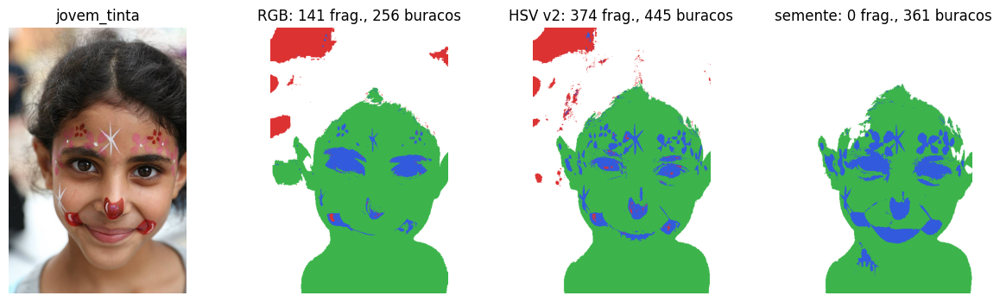


mulher
  RGB      regiões= 424 | fragmentos= 423 (área típica 1 px, maior 176 px) | buracos= 251 (área típica 1 px, maior 7000 px) | erro do fundo em fragmentos: 12%
  HSV v2   regiões= 832 | fragmentos= 831 (área típica 1 px, maior 4114 px) | buracos=1313 (área típica 1 px, maior 2572 px) | erro do fundo em fragmentos: 18%
  semente  regiões=   1 | fragmentos=   0 (área típica 0 px, maior 0 px) | buracos= 925 (área típica 1 px, maior 13274 px) | erro do fundo em fragmentos: 0%


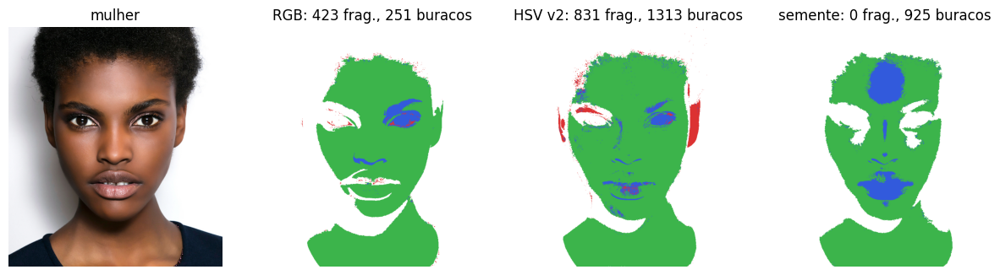


homem
  RGB      regiões= 422 | fragmentos= 421 (área típica 2 px, maior 930 px) | buracos= 507 (área típica 2 px, maior 16468 px) | erro do fundo em fragmentos: 38%
  HSV v2   regiões= 912 | fragmentos= 911 (área típica 2 px, maior 10066 px) | buracos= 757 (área típica 2 px, maior 2606 px) | erro do fundo em fragmentos: 46%
  semente  regiões=   1 | fragmentos=   0 (área típica 0 px, maior 0 px) | buracos= 976 (área típica 2 px, maior 5906 px) | erro do fundo em fragmentos: 0%


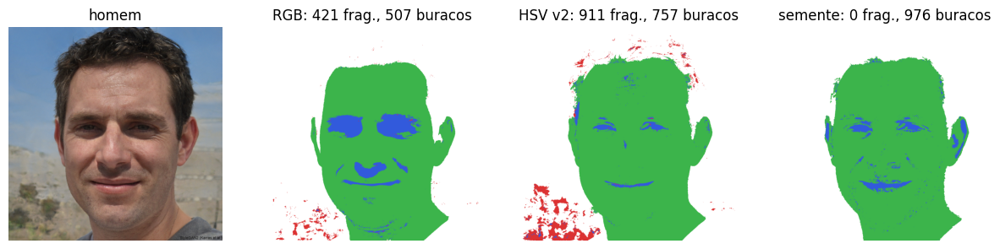

In [25]:
MASCARAS_MORF = {'RGB': lambda n, img: regra_rgb(img),
                 'HSV v2': lambda n, img: regra_hsv_v2(img, v_min=V_MIN, s_min=S_MIN),
                 'semente': seg_h1}

for nome, img in IMGS.items():
    print(f"\n{nome}")
    fig, ax = plt.subplots(1, 4, figsize=(15, 4))
    ax[0].imshow(img); ax[0].set_title(nome); ax[0].axis('off')
    for a, (rot_m, f) in zip(ax[1:], MASCARAS_MORF.items()):
        m = f(nome, img)
        principal, fragmentos, buracos, a_frag, a_bur = descrever(m)
        fp = m & ~MASCARAS[nome] & VALIDO[nome]
        print(f"  {rot_m:8s} regiões={len(a_frag) + 1:4d} | fragmentos={len(a_frag):4d} "
              f"(área típica {np.median(a_frag) if len(a_frag) else 0:.0f} px, maior {a_frag.max() if len(a_frag) else 0} px) | "
              f"buracos={len(a_bur):4d} (área típica {np.median(a_bur):.0f} px, maior {a_bur.max()} px) | "
              f"erro do fundo em fragmentos: {(fp & fragmentos).sum() / max(fp.sum(), 1) * 100:.0f}%")
        vis = np.full(m.shape + (3,), 255, np.uint8)
        vis[principal] = (60, 180, 75)      # verde = região principal
        vis[fragmentos] = (220, 50, 50)     # vermelho = fragmentos soltos
        vis[buracos] = (50, 90, 220)        # azul = buracos
        a.imshow(vis); a.set_title(f"{rot_m}: {len(a_frag)} frag., {len(a_bur)} buracos"); a.axis('off')
    plt.show()

# Operações Morfológicas

In [58]:
def elemento(forma, r):
    """Deslocamentos (dy, dx) do elemento estruturante: 'cruz', 'quadrado' ou 'disco' de raio r."""
    if forma == 'quadrado':
        return [(dy, dx) for dy in range(-r, r + 1) for dx in range(-r, r + 1)]
    if forma == 'disco':
        return [(dy, dx) for dy in range(-r, r + 1) for dx in range(-r, r + 1) if dy * dy + dx * dx <= r * r]
    return [(d, 0) for d in range(-r, r + 1)] + [(0, d) for d in range(-r, r + 1) if d != 0]

def deslocar(m, dy, dx, fora):
    """Máscara deslocada em (dy, dx); o que entra pela borda recebe o valor `fora`."""
    h, w = m.shape
    r = max(abs(dy), abs(dx))
    p = np.pad(m, r, constant_values=fora)
    return p[r + dy:r + dy + h, r + dx:r + dx + w]

def erosao(m, forma, r):
    """Pixel fica se o elemento inteiro, centrado nele, couber na máscara (E lógico dos deslocamentos)."""
    out = np.ones_like(m)
    for dy, dx in elemento(forma, r):
        out &= deslocar(m, dy, dx, fora=True)     # fora da imagem não erode a borda
    return out

def dilatacao(m, forma, r):
    """Pixel entra se o elemento, centrado nele, tocar a máscara (OU lógico dos deslocamentos)."""
    out = np.zeros_like(m)
    for dy, dx in elemento(forma, r):
        out |= deslocar(m, dy, dx, fora=False)
    return out

def abertura(m, forma, r):
    return dilatacao(erosao(m, forma, r), forma, r)    # remove o que é menor que o elemento

def fechamento(m, forma, r):
    return erosao(dilatacao(m, forma, r), forma, r)    # preenche o que é menor que o elemento

# validação contra o scipy (usado para conferir a implementação)
from scipy import ndimage as ndi
teste = regra_hsv_v2(IMGS['mulher'], v_min=V_MIN, s_min=S_MIN)
for forma, r in [('cruz', 1), ('quadrado', 2), ('disco', 3)]:
    el = np.zeros((2 * r + 1, 2 * r + 1), bool)
    for dy, dx in elemento(forma, r):
        el[dy + r, dx + r] = True
    ok_e = np.array_equal(erosao(teste, forma, r), ndimage.binary_erosion(teste, el, border_value=1))
    ok_d = np.array_equal(dilatacao(teste, forma, r), ndimage.binary_dilation(teste, el, border_value=0))
    print(f"{forma} r={r}: erosão igual ao scipy={ok_e}  dilatação igual ao scipy={ok_d}")

cruz r=1: erosão igual ao scipy=True  dilatação igual ao scipy=True
quadrado r=2: erosão igual ao scipy=True  dilatação igual ao scipy=True
disco r=3: erosão igual ao scipy=True  dilatação igual ao scipy=True


# Avaliação e máscara de entrada

Para cada máscara, o menor elemento que reduz o número de regiões e de buracos sem que a precisão mínima ou o recall mínimo (entre as 4 imagens) caiam mais de 0,02 em relação a “sem morfologia”. Em empate, o de menor raio.

In [59]:
def avaliar_mascara(nome, m):
    mt = metricas(m, MASCARAS[nome], ~VALIDO[nome])
    _, _, _, a_frag, a_bur = descrever(m)
    mt['regioes'] = len(a_frag) + 1
    mt['buracos'] = len(a_bur)
    return mt

def linha(rotulo, res):
    """Imprime uma linha por configuração: IoU por imagem, médias e estrutura."""
    print(f"{rotulo:30s}" + " ".join(f"{n}={r['iou']:.3f}" for n, r in res.items())
          + f" | IoU médio={np.mean([r['iou'] for r in res.values()]):.3f}"
          + f" prec mín={min(r['prec'] for r in res.values()):.2f}"
          + f" rec mín={min(r['rec'] for r in res.values()):.2f}"
          + f" | regiões={sum(r['regioes'] for r in res.values()):5d}"
          + f" buracos={sum(r['buracos'] for r in res.values()):5d}")

ENTRADAS = {'RGB':     lambda n, img: regra_rgb(img),
            'HSV v2':  lambda n, img: regra_hsv_v2(img, v_min=V_MIN, s_min=S_MIN),
            'semente': seg_h1}
BASE = {k: {n: f(n, img) for n, img in IMGS.items()} for k, f in ENTRADAS.items()}   # máscaras sem morfologia

# Varredura na abertura

In [60]:
# ---------- Célula 3: abertura (varredura de forma e raio) ----------
FORMAS = ['cruz', 'quadrado', 'disco']
RAIOS = [1, 2, 3, 5]
ABERT, SEM = {}, {}
for entrada in ['RGB', 'HSV v2', 'semente']:
    print(f"\n--- abertura sobre {entrada}")
    SEM[entrada] = {n: avaliar_mascara(n, BASE[entrada][n]) for n in IMGS}   # guardado para tabela e figura
    linha("sem morfologia", SEM[entrada])
    for forma in FORMAS:
        for r in RAIOS:
            res = {n: avaliar_mascara(n, abertura(BASE[entrada][n], forma, r)) for n in IMGS}
            ABERT[(entrada, forma, r)] = res
            linha(f"abertura {forma} r={r}", res)


--- abertura sobre RGB
sem morfologia                jovem=0.467 jovem_tinta=0.665 mulher=0.741 homem=0.877 | IoU médio=0.687 prec mín=0.47 rec mín=0.78 | regiões= 1853 buracos= 1945
abertura cruz r=1             jovem=0.471 jovem_tinta=0.669 mulher=0.742 homem=0.879 | IoU médio=0.690 prec mín=0.48 rec mín=0.78 | regiões=  399 buracos= 1312
abertura cruz r=2             jovem=0.475 jovem_tinta=0.671 mulher=0.742 homem=0.880 | IoU médio=0.692 prec mín=0.48 rec mín=0.78 | regiões=  181 buracos= 1162
abertura cruz r=3             jovem=0.478 jovem_tinta=0.672 mulher=0.743 homem=0.882 | IoU médio=0.694 prec mín=0.48 rec mín=0.78 | regiões=   98 buracos= 1097
abertura cruz r=5             jovem=0.483 jovem_tinta=0.675 mulher=0.744 homem=0.884 | IoU médio=0.697 prec mín=0.49 rec mín=0.78 | regiões=   53 buracos=  948
abertura quadrado r=1         jovem=0.472 jovem_tinta=0.670 mulher=0.742 homem=0.878 | IoU médio=0.691 prec mín=0.48 rec mín=0.78 | regiões=  272 buracos=  843
abertura quadrad

Figura para ilustrar os resultados da varredura de abertura

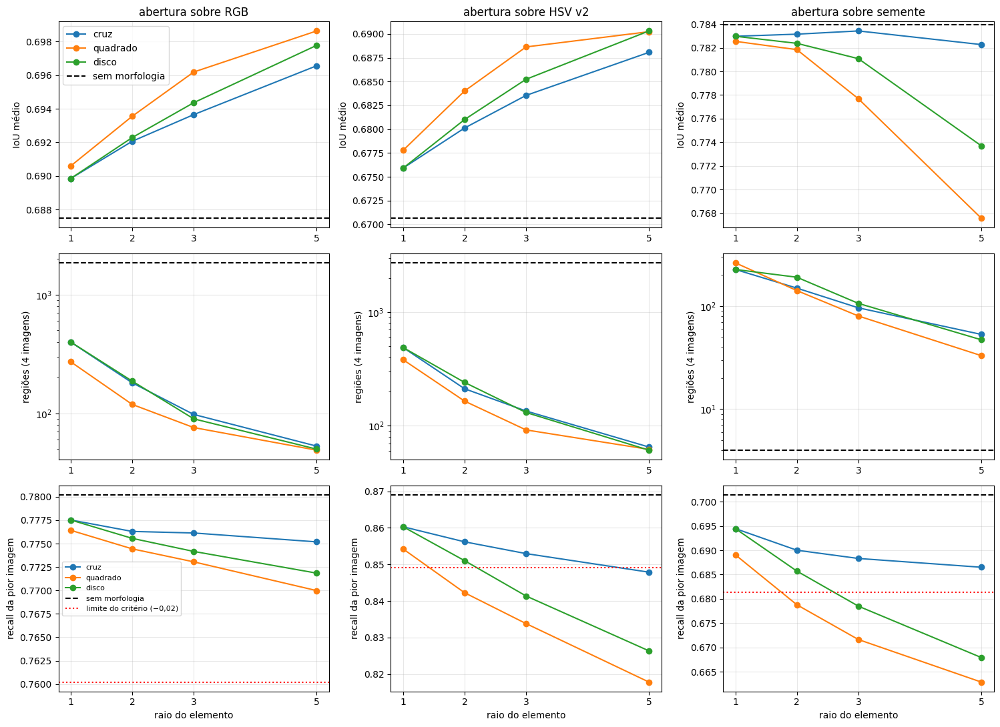

In [61]:
fig, ax = plt.subplots(3, 3, figsize=(15, 11))
for j, entrada in enumerate(['RGB', 'HSV v2', 'semente']):
    rec_ref = min(SEM[entrada][n]['rec'] for n in IMGS)
    for forma in FORMAS:
        ax[0, j].plot(RAIOS, [np.mean([ABERT[(entrada, forma, r)][n]['iou'] for n in IMGS]) for r in RAIOS], 'o-', label=forma)
        ax[1, j].plot(RAIOS, [sum(ABERT[(entrada, forma, r)][n]['regioes'] for n in IMGS) for r in RAIOS], 'o-', label=forma)
        ax[2, j].plot(RAIOS, [min(ABERT[(entrada, forma, r)][n]['rec'] for n in IMGS) for r in RAIOS], 'o-', label=forma)
    ax[0, j].axhline(np.mean([SEM[entrada][n]['iou'] for n in IMGS]), color='k', ls='--', label='sem morfologia')
    ax[1, j].axhline(sum(SEM[entrada][n]['regioes'] for n in IMGS), color='k', ls='--', label='sem morfologia')
    ax[2, j].axhline(rec_ref, color='k', ls='--', label='sem morfologia')
    ax[2, j].axhline(rec_ref - 0.02, color='red', ls=':', label='limite do critério (−0,02)')
    ax[0, j].set_title(f"abertura sobre {entrada}")
    ax[0, j].set_ylabel('IoU médio'); ax[1, j].set_ylabel('regiões (4 imagens)'); ax[2, j].set_ylabel('recall da pior imagem')
    ax[1, j].set_yscale('log'); ax[2, j].set_xlabel('raio do elemento')
    for a in ax[:, j]: a.grid(alpha=.3); a.set_xticks(RAIOS)
ax[0, 0].legend(); ax[2, 0].legend(fontsize=8); plt.tight_layout(); plt.show()

Ilustração de como as imagens são afetadas pelo elemento escolhido

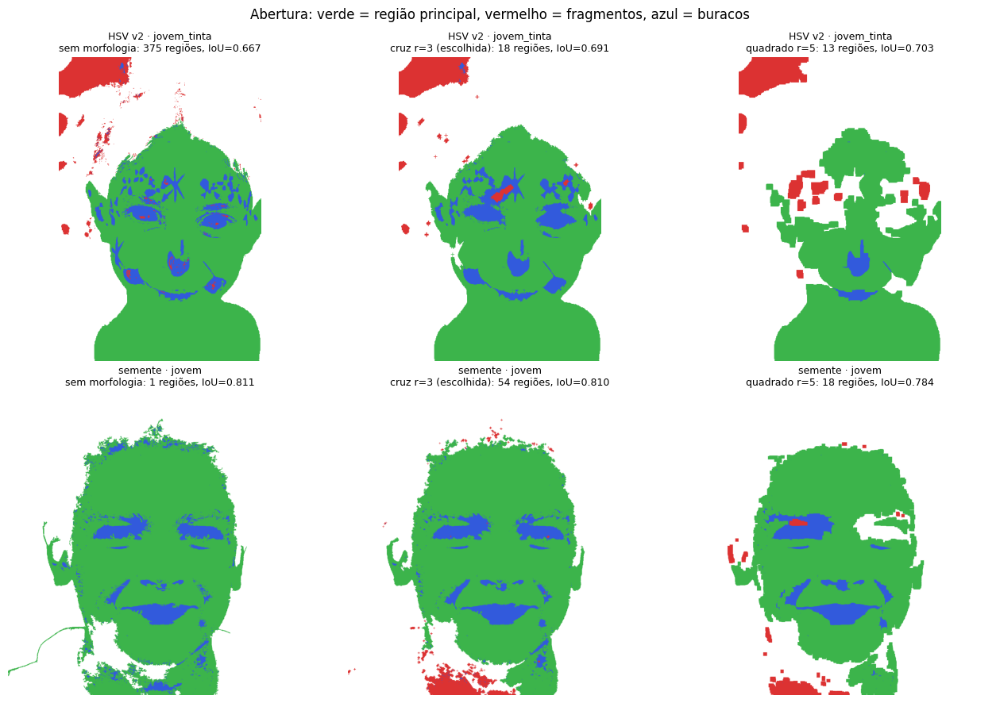

In [62]:
CASOS = [('HSV v2', 'jovem_tinta'), ('semente', 'jovem')]
CONFIGS = [('sem morfologia', None), ('cruz r=3 (escolhida)', ('cruz', 3)), ('quadrado r=5', ('quadrado', 5))]

fig, ax = plt.subplots(len(CASOS), len(CONFIGS), figsize=(13, 9))
for i, (entrada, nome) in enumerate(CASOS):
    for j, (rotulo, el) in enumerate(CONFIGS):
        m = BASE[entrada][nome] if el is None else abertura(BASE[entrada][nome], *el)
        principal, fragmentos, buracos, a_frag, a_bur = descrever(m)
        vis = np.full(m.shape + (3,), 255, np.uint8)
        vis[principal] = (60, 180, 75); vis[fragmentos] = (220, 50, 50); vis[buracos] = (50, 90, 220)
        iou = metricas(m, MASCARAS[nome], ~VALIDO[nome])['iou']
        ax[i, j].imshow(vis); ax[i, j].axis('off')
        ax[i, j].set_title(f"{entrada} · {nome}\n{rotulo}: {len(a_frag) + 1} regiões, IoU={iou:.3f}", fontsize=9)
fig.suptitle('Abertura: verde = região principal, vermelho = fragmentos, azul = buracos')
plt.tight_layout(); plt.show()

# Varredura no fechamento

In [63]:
ABERTURA_ESC = {'RGB': ('cruz', 3), 'HSV v2': ('cruz', 3)}   # <- escolha de vocês na célula 3
FECH = {}
for entrada in ['RGB', 'HSV v2', 'semente']:
    if entrada in ABERTURA_ESC:
        f_a, r_a = ABERTURA_ESC[entrada]
        ponto_partida = {n: abertura(BASE[entrada][n], f_a, r_a) for n in IMGS}
        print(f"\n--- fechamento sobre {entrada} (após abertura {f_a} r={r_a})")
    else:
        ponto_partida = BASE[entrada]                    # semente: fechamento direto, sem abertura
        print(f"\n--- fechamento sobre {entrada}")
    linha("ponto de partida", {n: avaliar_mascara(n, ponto_partida[n]) for n in IMGS})
    for forma in FORMAS:
        for r in RAIOS:
            res = {n: avaliar_mascara(n, fechamento(ponto_partida[n], forma, r)) for n in IMGS}
            FECH[(entrada, forma, r)] = res
            linha(f"fechamento {forma} r={r}", res)


--- fechamento sobre RGB (após abertura cruz r=3)
ponto de partida              jovem=0.478 jovem_tinta=0.672 mulher=0.743 homem=0.882 | IoU médio=0.694 prec mín=0.48 rec mín=0.78 | regiões=   98 buracos= 1097
fechamento cruz r=1           jovem=0.475 jovem_tinta=0.671 mulher=0.744 homem=0.884 | IoU médio=0.694 prec mín=0.48 rec mín=0.78 | regiões=   83 buracos=  239
fechamento cruz r=2           jovem=0.474 jovem_tinta=0.671 mulher=0.744 homem=0.886 | IoU médio=0.694 prec mín=0.48 rec mín=0.78 | regiões=  103 buracos=  119
fechamento cruz r=3           jovem=0.474 jovem_tinta=0.672 mulher=0.745 homem=0.887 | IoU médio=0.695 prec mín=0.48 rec mín=0.78 | regiões=   97 buracos=   89
fechamento cruz r=5           jovem=0.470 jovem_tinta=0.674 mulher=0.749 homem=0.889 | IoU médio=0.695 prec mín=0.47 rec mín=0.78 | regiões=   88 buracos=   48
fechamento quadrado r=1       jovem=0.475 jovem_tinta=0.671 mulher=0.744 homem=0.885 | IoU médio=0.694 prec mín=0.48 rec mín=0.78 | regiões=   83 bur

Figura para ilustrar os resultados da varredura de fechamento

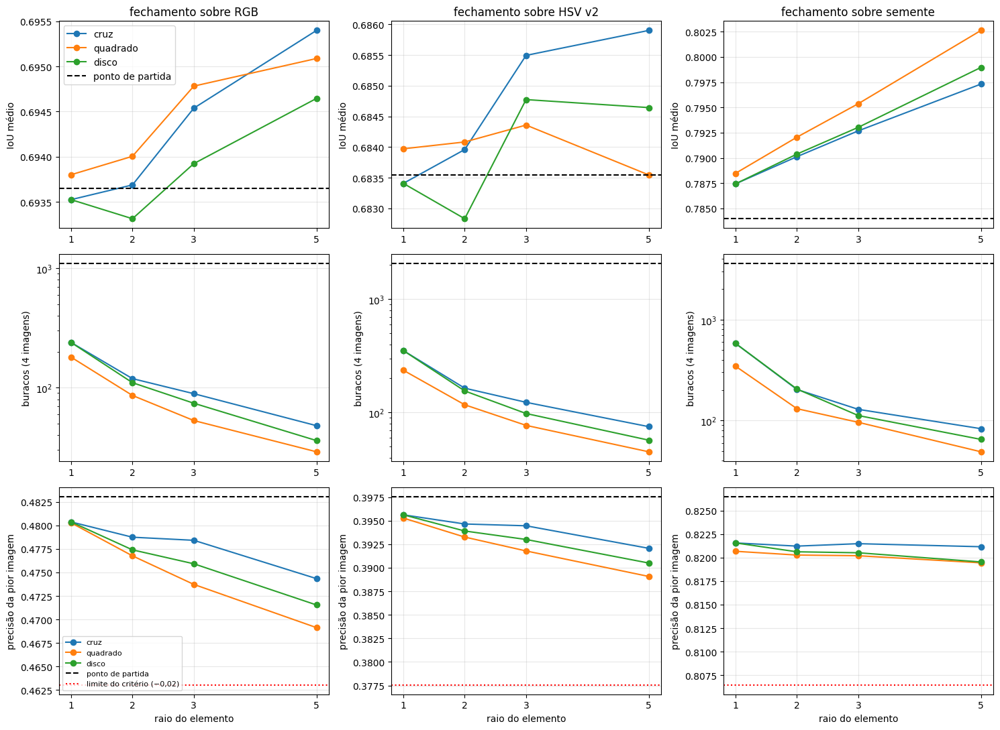

In [64]:
PARTIDA = {e: {n: avaliar_mascara(n, abertura(BASE[e][n], *ABERTURA_ESC[e])) for n in IMGS} for e in ABERTURA_ESC}
PARTIDA['semente'] = SEM['semente']

fig, ax = plt.subplots(3, 3, figsize=(15, 11))
for j, entrada in enumerate(['RGB', 'HSV v2', 'semente']):
    prec_ref = min(PARTIDA[entrada][n]['prec'] for n in IMGS)
    for forma in FORMAS:
        ax[0, j].plot(RAIOS, [np.mean([FECH[(entrada, forma, r)][n]['iou'] for n in IMGS]) for r in RAIOS], 'o-', label=forma)
        ax[1, j].plot(RAIOS, [sum(FECH[(entrada, forma, r)][n]['buracos'] for n in IMGS) for r in RAIOS], 'o-', label=forma)
        ax[2, j].plot(RAIOS, [min(FECH[(entrada, forma, r)][n]['prec'] for n in IMGS) for r in RAIOS], 'o-', label=forma)
    ax[0, j].axhline(np.mean([PARTIDA[entrada][n]['iou'] for n in IMGS]), color='k', ls='--', label='ponto de partida')
    ax[1, j].axhline(sum(PARTIDA[entrada][n]['buracos'] for n in IMGS), color='k', ls='--', label='ponto de partida')
    ax[2, j].axhline(prec_ref, color='k', ls='--', label='ponto de partida')
    ax[2, j].axhline(prec_ref - 0.02, color='red', ls=':', label='limite do critério (−0,02)')
    ax[0, j].set_title(f"fechamento sobre {entrada}")
    ax[0, j].set_ylabel('IoU médio'); ax[1, j].set_ylabel('buracos (4 imagens)'); ax[2, j].set_ylabel('precisão da pior imagem')
    ax[1, j].set_yscale('log'); ax[2, j].set_xlabel('raio do elemento')
    for a in ax[:, j]: a.grid(alpha=.3); a.set_xticks(RAIOS)
ax[0, 0].legend(); ax[2, 0].legend(fontsize=8); plt.tight_layout(); plt.show()

Ilustração de como as imagens são afetadas pelo elemento escolhido

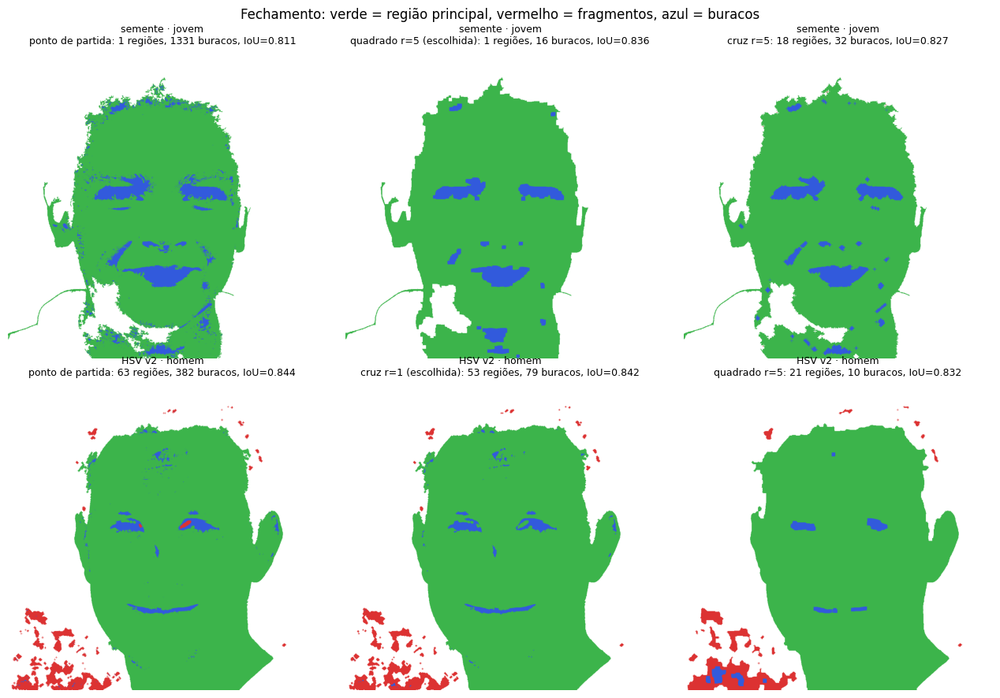

In [65]:
CASOS_F = [('semente', 'jovem', [('ponto de partida', None), ('quadrado r=5 (escolhida)', ('quadrado', 5)), ('cruz r=5', ('cruz', 5))]),
           ('HSV v2', 'homem',  [('ponto de partida', None), ('cruz r=1 (escolhida)', ('cruz', 1)), ('quadrado r=5', ('quadrado', 5))])]

fig, ax = plt.subplots(2, 3, figsize=(13, 9))
for i, (entrada, nome, configs) in enumerate(CASOS_F):
    inicio = BASE[entrada][nome] if entrada == 'semente' else abertura(BASE[entrada][nome], *ABERTURA_ESC[entrada])
    for j, (rotulo, el) in enumerate(configs):
        m = inicio if el is None else fechamento(inicio, *el)
        principal, fragmentos, buracos, a_frag, a_bur = descrever(m)
        vis = np.full(m.shape + (3,), 255, np.uint8)
        vis[principal] = (60, 180, 75); vis[fragmentos] = (220, 50, 50); vis[buracos] = (50, 90, 220)
        mt = metricas(m, MASCARAS[nome], ~VALIDO[nome])
        ax[i, j].imshow(vis); ax[i, j].axis('off')
        ax[i, j].set_title(f"{entrada} · {nome}\n{rotulo}: {len(a_frag) + 1} regiões, {len(a_bur)} buracos, IoU={mt['iou']:.3f}", fontsize=9)
fig.suptitle('Fechamento: verde = região principal, vermelho = fragmentos, azul = buracos')
plt.tight_layout(); plt.show()

# Inversão da ordem

In [66]:
ABERTURA_ESC   = {'RGB': ('cruz', 3), 'HSV v2': ('cruz', 3)}
FECHAMENTO_ESC = {'RGB': ('cruz', 1), 'HSV v2': ('cruz', 1)}

ORDENS = {'sem morfologia':        lambda m, a, f: m,
          'abertura → fechamento': lambda m, a, f: fechamento(abertura(m, *a), *f),
          'fechamento → abertura': lambda m, a, f: abertura(fechamento(m, *f), *a)}
INV = {}
for entrada in ['RGB', 'HSV v2']:
    a, f = ABERTURA_ESC[entrada], FECHAMENTO_ESC[entrada]
    print(f"\n--- {entrada}: abertura {a}, fechamento {f}")
    for rotulo, op in ORDENS.items():
        INV[(entrada, rotulo)] = {n: avaliar_mascara(n, op(BASE[entrada][n], a, f)) for n in IMGS}
        linha(rotulo, INV[(entrada, rotulo)])


--- RGB: abertura ('cruz', 3), fechamento ('cruz', 1)
sem morfologia                jovem=0.467 jovem_tinta=0.665 mulher=0.741 homem=0.877 | IoU médio=0.687 prec mín=0.47 rec mín=0.78 | regiões= 1853 buracos= 1945
abertura → fechamento         jovem=0.475 jovem_tinta=0.671 mulher=0.744 homem=0.884 | IoU médio=0.694 prec mín=0.48 rec mín=0.78 | regiões=   83 buracos=  239
fechamento → abertura         jovem=0.471 jovem_tinta=0.667 mulher=0.745 homem=0.885 | IoU médio=0.692 prec mín=0.48 rec mín=0.78 | regiões=   83 buracos=  302

--- HSV v2: abertura ('cruz', 3), fechamento ('cruz', 1)
sem morfologia                jovem=0.392 jovem_tinta=0.667 mulher=0.800 homem=0.825 | IoU médio=0.671 prec mín=0.39 rec mín=0.87 | regiões= 2720 buracos= 3819
abertura → fechamento         jovem=0.395 jovem_tinta=0.690 mulher=0.806 homem=0.842 | IoU médio=0.683 prec mín=0.40 rec mín=0.86 | regiões=  113 buracos=  352
fechamento → abertura         jovem=0.392 jovem_tinta=0.677 mulher=0.810 homem=0.835 | 

Figura para ilustrar os resultados da inversão de ordem

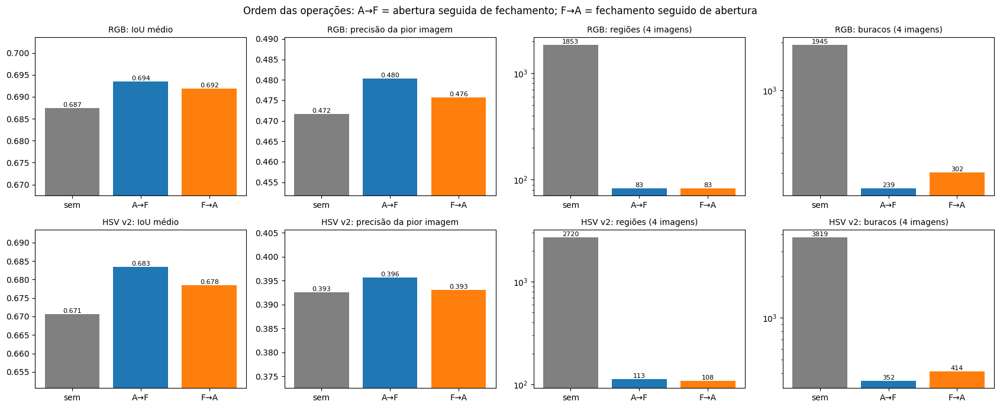

In [67]:
metr = [('IoU médio', lambda res: np.mean([x['iou'] for x in res.values()])),
        ('precisão da pior imagem', lambda res: min(x['prec'] for x in res.values())),
        ('regiões (4 imagens)', lambda res: sum(x['regioes'] for x in res.values())),
        ('buracos (4 imagens)', lambda res: sum(x['buracos'] for x in res.values()))]
cores = ['gray', 'tab:blue', 'tab:orange']
fig, ax = plt.subplots(2, 4, figsize=(17, 7))
for i, entrada in enumerate(['RGB', 'HSV v2']):
    for j, (nome_m, f) in enumerate(metr):
        valores = [f(INV[(entrada, r)]) for r in ORDENS]
        barras = ax[i, j].bar(range(3), valores, color=cores)
        ax[i, j].bar_label(barras, fmt='%.3f' if valores[0] < 2 else '%d', fontsize=8)
        ax[i, j].set_xticks(range(3)); ax[i, j].set_xticklabels(['sem', 'A→F', 'F→A'])
        ax[i, j].set_title(f"{entrada}: {nome_m}", fontsize=10)
        if j < 2: ax[i, j].set_ylim(min(valores) - 0.02, max(valores) + 0.01)
        else: ax[i, j].set_yscale('log')
fig.suptitle('Ordem das operações: A→F = abertura seguida de fechamento; F→A = fechamento seguido de abertura')
plt.tight_layout(); plt.show()

Ilustração de como as imagens são afetadas pela inversão de ordem

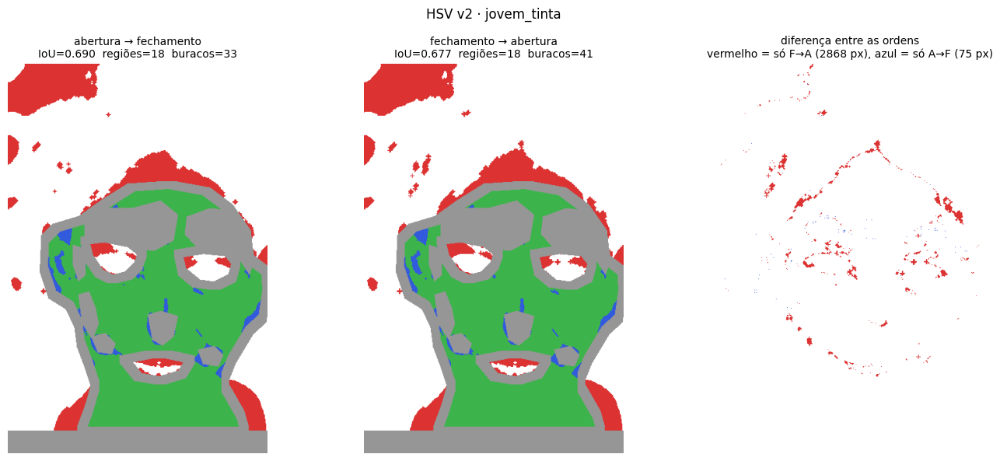

In [68]:
entrada, nome = 'HSV v2', 'jovem_tinta'
a, f = ABERTURA_ESC[entrada], FECHAMENTO_ESC[entrada]
m_af = fechamento(abertura(BASE[entrada][nome], *a), *f)
m_fa = abertura(fechamento(BASE[entrada][nome], *f), *a)

fig, ax = plt.subplots(1, 3, figsize=(14, 6))
for k, (rotulo, m) in enumerate([('abertura → fechamento', m_af), ('fechamento → abertura', m_fa)]):
    mt = INV[(entrada, rotulo)][nome]
    ax[k].imshow(mapa_erro(m, MASCARAS[nome], ~VALIDO[nome]))
    ax[k].set_title(f"{rotulo}\nIoU={mt['iou']:.3f}  regiões={mt['regioes']}  buracos={mt['buracos']}", fontsize=10)
dif = np.full(m_af.shape + (3,), 255, np.uint8)
dif[m_fa & ~m_af] = (220, 50, 50)      # só na ordem invertida
dif[m_af & ~m_fa] = (50, 90, 220)      # só na ordem usada
ax[2].imshow(dif); ax[2].set_title(f"diferença entre as ordens\nvermelho = só F→A ({(m_fa & ~m_af).sum()} px), azul = só A→F ({(m_af & ~m_fa).sum()} px)", fontsize=10)
for x in ax: x.axis('off')
fig.suptitle(f"{entrada} · {nome}"); plt.tight_layout(); plt.show()

# Comparação com e sem Morfologia

entrada   imagem                 IoU      precisão        recall     regiões     buracos
RGB       jovem        0.467→0.475  0.472→0.480  0.979→0.978   865→  39   931→ 143
RGB       jovem_tinta  0.665→0.671  0.687→0.693  0.954→0.954   142→   7   256→  29
RGB       mulher       0.741→0.744  0.936→0.945  0.780→0.778   424→   5   251→   4
RGB       homem        0.877→0.884  0.949→0.959  0.920→0.919   422→  32   507→  63
          MÉDIA        0.687→0.694

HSV v2    jovem        0.392→0.395  0.393→0.396  0.994→0.994   601→  24  1304→ 196
HSV v2    jovem_tinta  0.667→0.690  0.690→0.715  0.952→0.953   375→  18   445→  33
HSV v2    mulher       0.800→0.806  0.909→0.928  0.869→0.860   832→  18  1313→  44
HSV v2    homem        0.825→0.842  0.841→0.860  0.977→0.977   912→  53   757→  79
          MÉDIA        0.671→0.683

semente   jovem        0.811→0.836  0.928→0.909  0.866→0.912     1→   1  1331→  16
semente   jovem_tinta  0.754→0.782  0.826→0.819  0.896→0.945     1→   1   361→  18
semente  

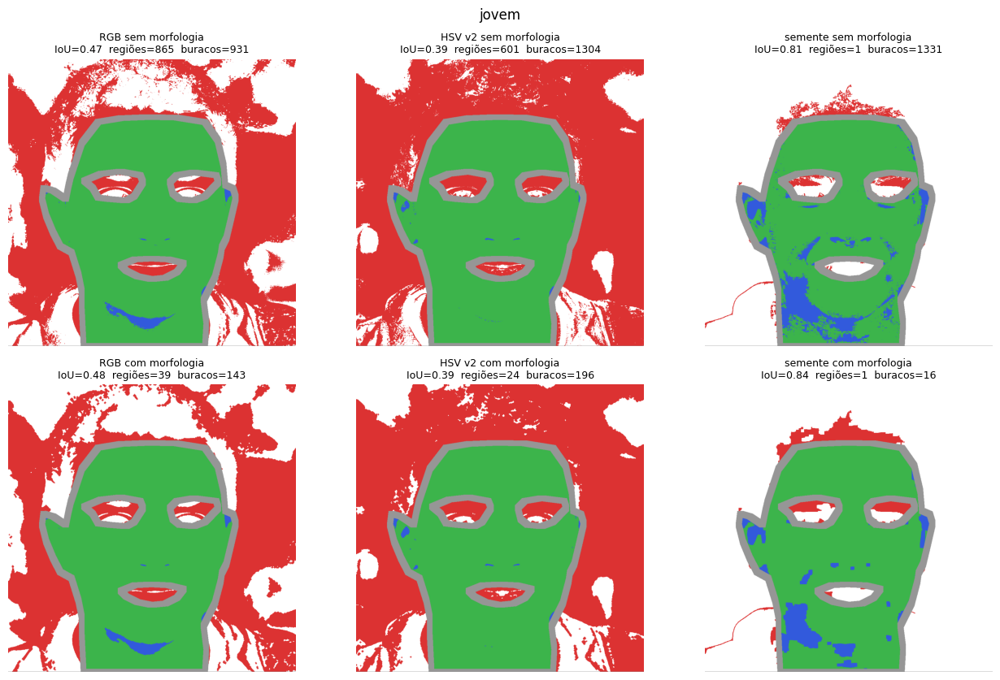

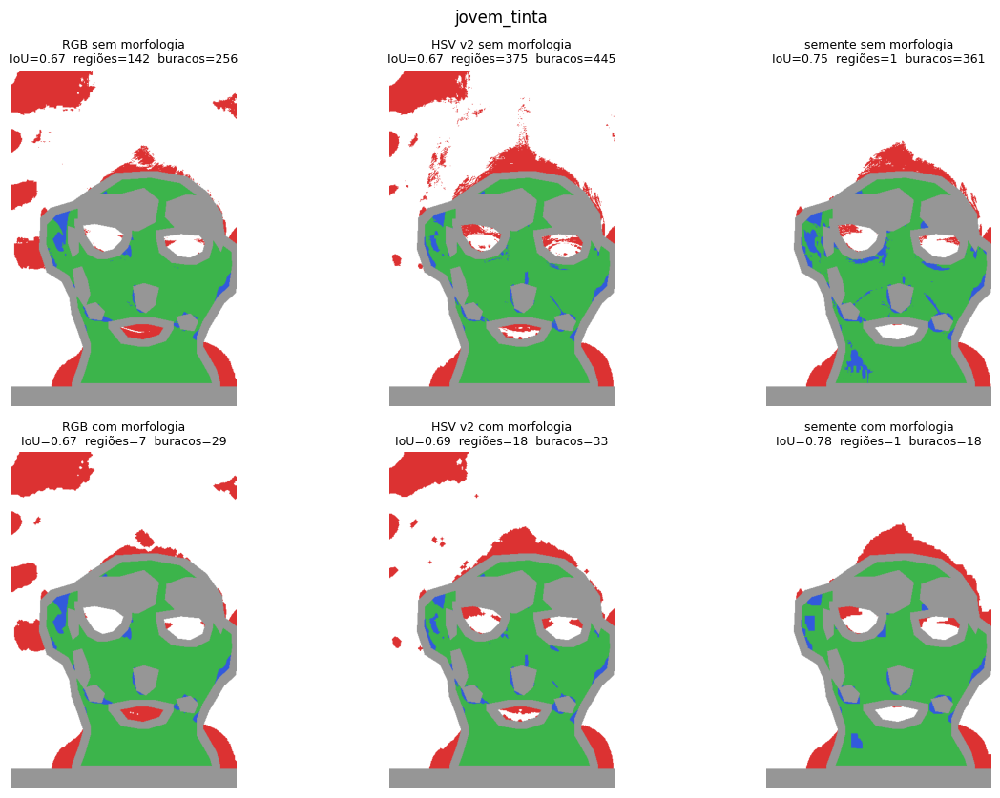

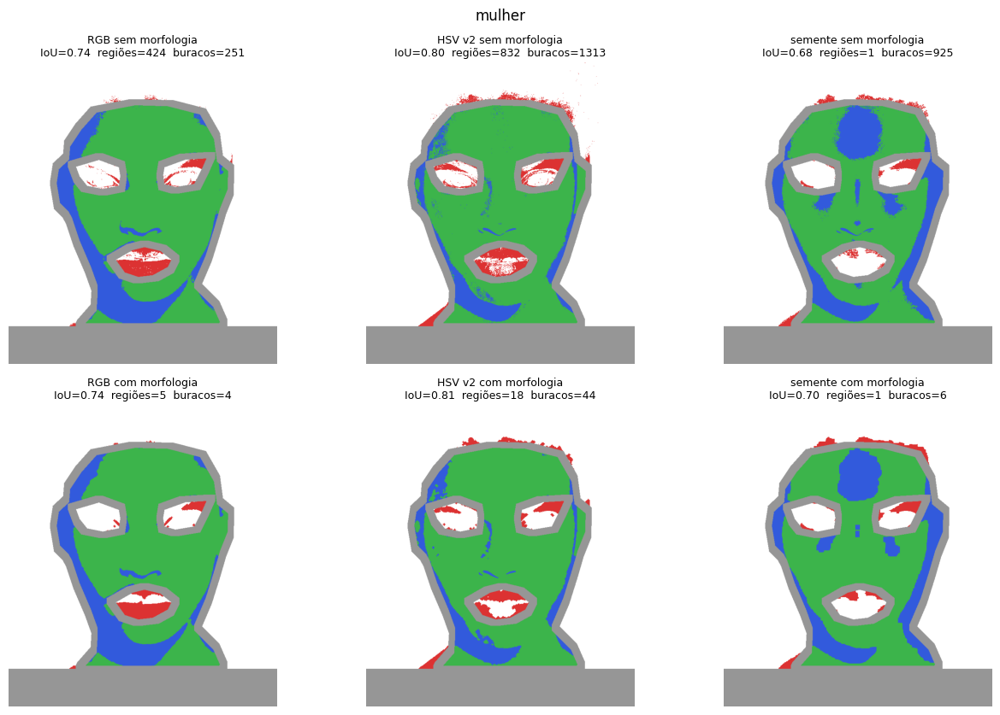

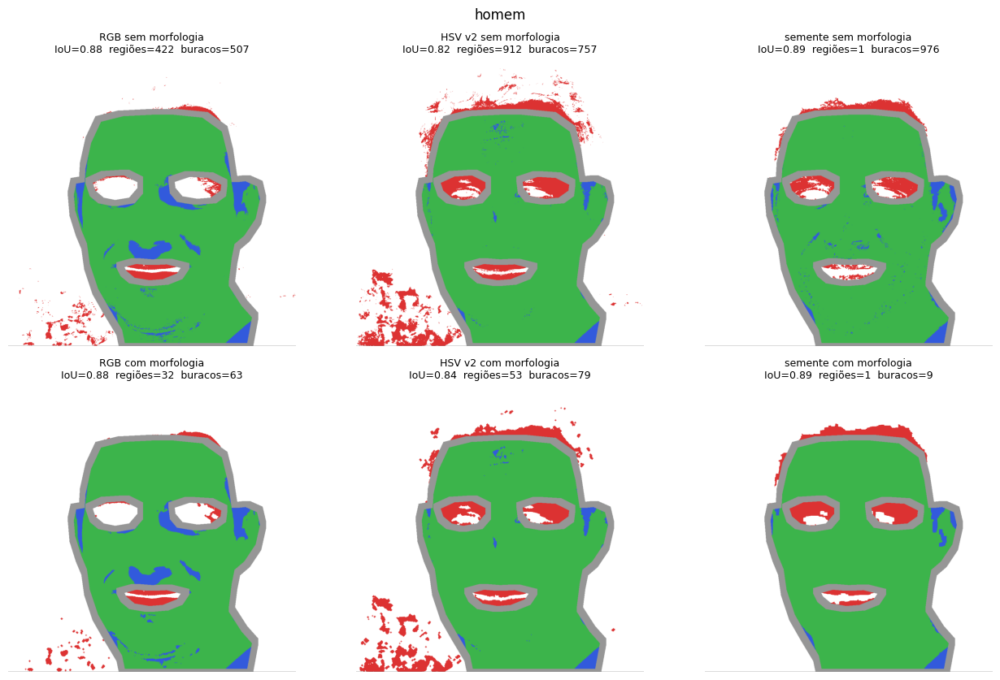

In [69]:
ESCOLHA = {
    'RGB':     (('cruz', 3), ('cruz', 1)),
    'HSV v2':  (('cruz', 3), ('cruz', 1)),
    'semente': (None,        ('quadrado', 5)),
}

def refinar(m, abert, fech):
    if abert: m = abertura(m, *abert)
    if fech:  m = fechamento(m, *fech)
    return m

FINAL = {}
for entrada, (abert, fech) in ESCOLHA.items():
    FINAL[(entrada, 'sem')] = {n: avaliar_mascara(n, BASE[entrada][n]) for n in IMGS}
    FINAL[(entrada, 'com')] = {n: avaliar_mascara(n, refinar(BASE[entrada][n], abert, fech)) for n in IMGS}

print(f"{'entrada':9s} {'imagem':12s} {'IoU':>13s} {'precisão':>13s} {'recall':>13s} {'regiões':>11s} {'buracos':>11s}")
for entrada in ESCOLHA:
    for n in IMGS:
        s, c = FINAL[(entrada, 'sem')][n], FINAL[(entrada, 'com')][n]
        print(f"{entrada:9s} {n:12s} {s['iou']:.3f}→{c['iou']:.3f}  {s['prec']:.3f}→{c['prec']:.3f}  "
              f"{s['rec']:.3f}→{c['rec']:.3f}  {s['regioes']:4d}→{c['regioes']:4d}  {s['buracos']:4d}→{c['buracos']:4d}")
    ms, mc = [np.mean([FINAL[(entrada, k)][n]['iou'] for n in IMGS]) for k in ('sem', 'com')]
    print(f"{'':9s} {'MÉDIA':12s} {ms:.3f}→{mc:.3f}\n")

# mapas de erro: linha de cima sem morfologia, linha de baixo com
for nome, img in IMGS.items():
    fig, ax = plt.subplots(2, 3, figsize=(13, 8.5))
    for j, (entrada, (abert, fech)) in enumerate(ESCOLHA.items()):
        for i, (rot, m) in enumerate([('sem', BASE[entrada][nome]), ('com', refinar(BASE[entrada][nome], abert, fech))]):
            mt = FINAL[(entrada, rot)][nome]
            ax[i, j].imshow(mapa_erro(m, MASCARAS[nome], ~VALIDO[nome]))
            ax[i, j].set_title(f"{entrada} {rot} morfologia\nIoU={mt['iou']:.2f}  regiões={mt['regioes']}  buracos={mt['buracos']}", fontsize=9)
            ax[i, j].axis('off')
    fig.suptitle(nome); plt.tight_layout(); plt.show()

Gráfico resumo

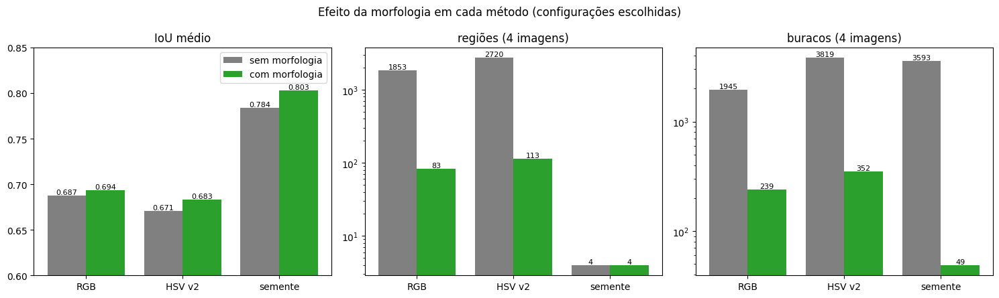

In [70]:
METODOS = list(ESCOLHA)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
for k, (titulo, f, log) in enumerate([('IoU médio', lambda r: np.mean([x['iou'] for x in r.values()]), False),
                                       ('regiões (4 imagens)', lambda r: sum(x['regioes'] for x in r.values()), True),
                                       ('buracos (4 imagens)', lambda r: sum(x['buracos'] for x in r.values()), True)]):
    sem = [f(FINAL[(e, 'sem')]) for e in METODOS]
    com = [f(FINAL[(e, 'com')]) for e in METODOS]
    x = np.arange(len(METODOS))
    b1 = ax[k].bar(x - 0.2, sem, 0.4, color='gray', label='sem morfologia')
    b2 = ax[k].bar(x + 0.2, com, 0.4, color='tab:green', label='com morfologia')
    fmt = '%d' if log else '%.3f'
    ax[k].bar_label(b1, fmt=fmt, fontsize=8); ax[k].bar_label(b2, fmt=fmt, fontsize=8)
    ax[k].set_xticks(x); ax[k].set_xticklabels(METODOS); ax[k].set_title(titulo)
    if log: ax[k].set_yscale('log')
    else: ax[k].set_ylim(0.6, 0.85)
ax[0].legend(); fig.suptitle('Efeito da morfologia em cada método (configurações escolhidas)')
plt.tight_layout(); plt.show()

Repetição com elemento diferente

entrada   imagem                 IoU      precisão        recall     regiões     buracos
RGB       jovem        0.467→0.465  0.472→0.469  0.979→0.981   865→  11   931→  12
RGB       jovem_tinta  0.665→0.673  0.687→0.688  0.954→0.968   142→   6   256→   5
RGB       mulher       0.741→0.752  0.936→0.943  0.780→0.788   424→   1   251→   3
RGB       homem        0.877→0.890  0.949→0.952  0.920→0.932   422→  16   507→   9
          MÉDIA        0.687→0.695

HSV v2    jovem        0.392→0.388  0.393→0.389  0.994→0.996   601→   5  1304→  22
HSV v2    jovem_tinta  0.667→0.693  0.690→0.706  0.952→0.974   375→  10   445→  10
HSV v2    mulher       0.800→0.821  0.909→0.920  0.869→0.885   832→   3  1313→   3
HSV v2    homem        0.825→0.832  0.841→0.844  0.977→0.983   912→  21   757→  10
          MÉDIA        0.671→0.684

semente   jovem        0.811→0.836  0.928→0.909  0.866→0.912     1→   1  1331→  16
semente   jovem_tinta  0.754→0.782  0.826→0.819  0.896→0.945     1→   1   361→  18
semente  

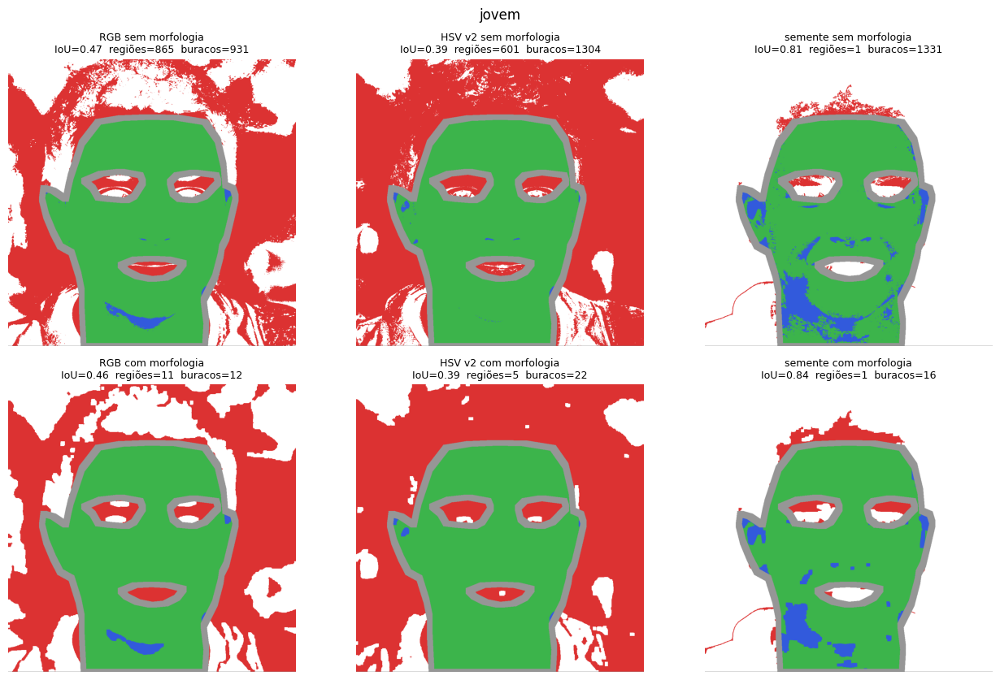

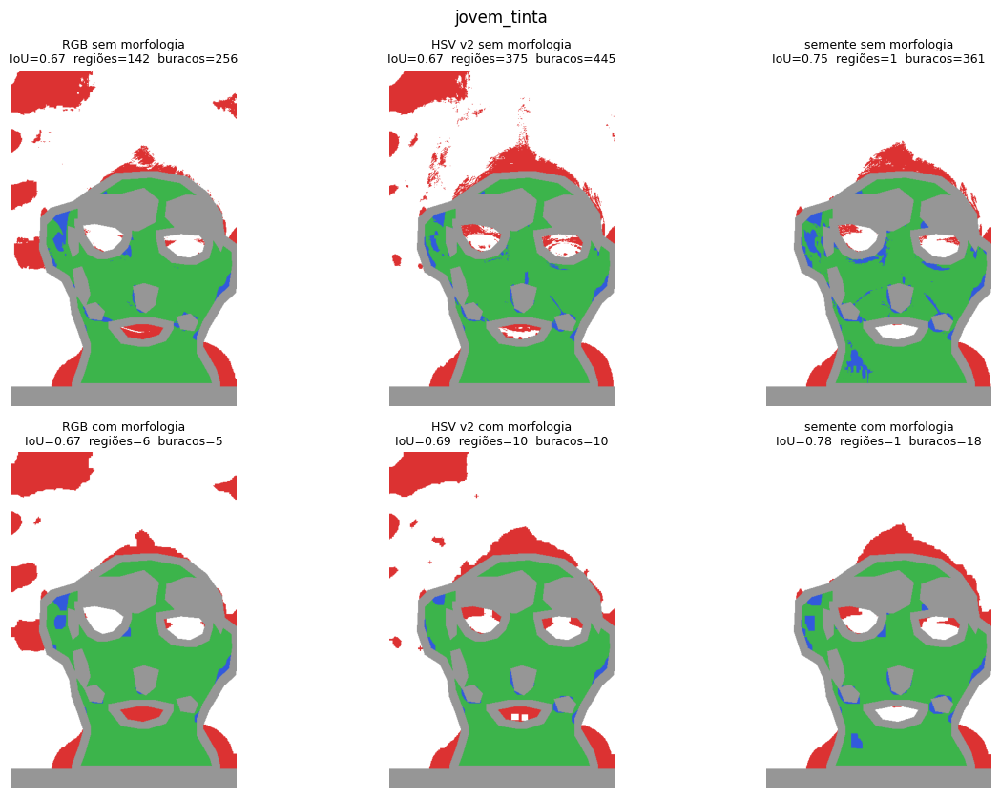

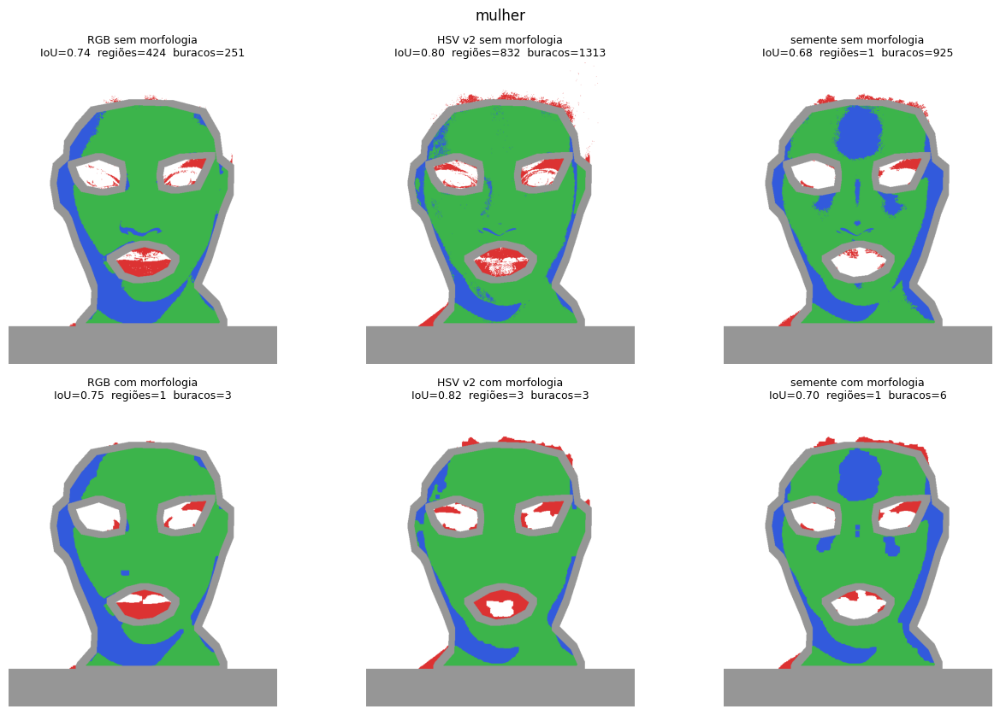

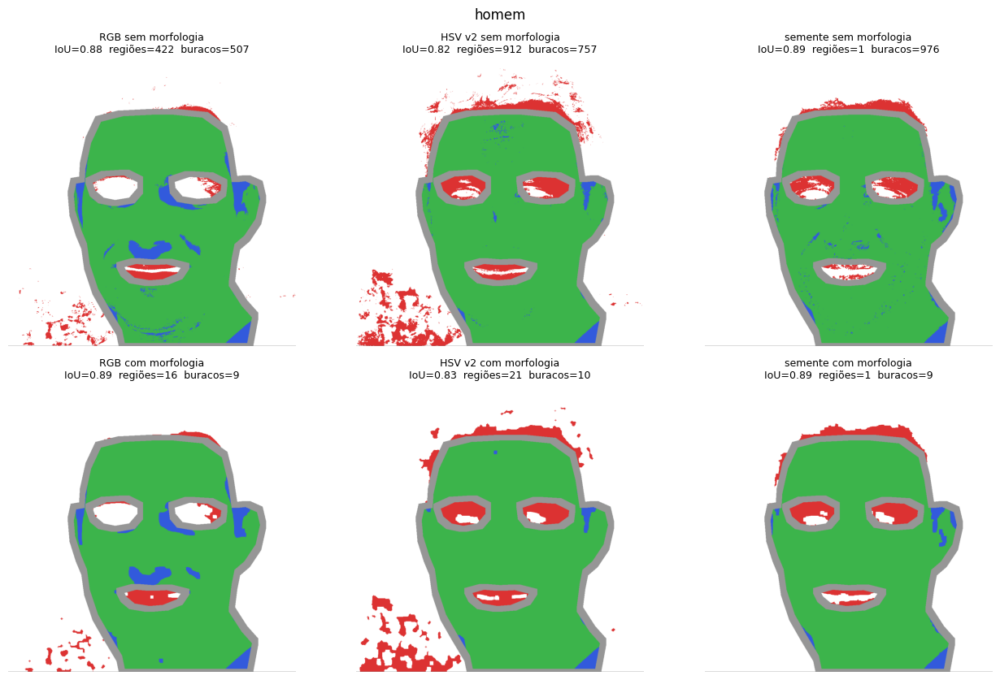

In [71]:
ESCOLHA = {
    'RGB':     (('cruz', 3), ('quadrado', 5)),
    'HSV v2':  (('cruz', 3), ('quadrado', 5)),
    'semente': (None,        ('quadrado', 5)),
}

def refinar(m, abert, fech):
    if abert: m = abertura(m, *abert)
    if fech:  m = fechamento(m, *fech)
    return m

FINAL = {}
for entrada, (abert, fech) in ESCOLHA.items():
    FINAL[(entrada, 'sem')] = {n: avaliar_mascara(n, BASE[entrada][n]) for n in IMGS}
    FINAL[(entrada, 'com')] = {n: avaliar_mascara(n, refinar(BASE[entrada][n], abert, fech)) for n in IMGS}

print(f"{'entrada':9s} {'imagem':12s} {'IoU':>13s} {'precisão':>13s} {'recall':>13s} {'regiões':>11s} {'buracos':>11s}")
for entrada in ESCOLHA:
    for n in IMGS:
        s, c = FINAL[(entrada, 'sem')][n], FINAL[(entrada, 'com')][n]
        print(f"{entrada:9s} {n:12s} {s['iou']:.3f}→{c['iou']:.3f}  {s['prec']:.3f}→{c['prec']:.3f}  "
              f"{s['rec']:.3f}→{c['rec']:.3f}  {s['regioes']:4d}→{c['regioes']:4d}  {s['buracos']:4d}→{c['buracos']:4d}")
    ms, mc = [np.mean([FINAL[(entrada, k)][n]['iou'] for n in IMGS]) for k in ('sem', 'com')]
    print(f"{'':9s} {'MÉDIA':12s} {ms:.3f}→{mc:.3f}\n")

# mapas de erro: linha de cima sem morfologia, linha de baixo com
for nome, img in IMGS.items():
    fig, ax = plt.subplots(2, 3, figsize=(13, 8.5))
    for j, (entrada, (abert, fech)) in enumerate(ESCOLHA.items()):
        for i, (rot, m) in enumerate([('sem', BASE[entrada][nome]), ('com', refinar(BASE[entrada][nome], abert, fech))]):
            mt = FINAL[(entrada, rot)][nome]
            ax[i, j].imshow(mapa_erro(m, MASCARAS[nome], ~VALIDO[nome]))
            ax[i, j].set_title(f"{entrada} {rot} morfologia\nIoU={mt['iou']:.2f}  regiões={mt['regioes']}  buracos={mt['buracos']}", fontsize=9)
            ax[i, j].axis('off')
    fig.suptitle(nome); plt.tight_layout(); plt.show()

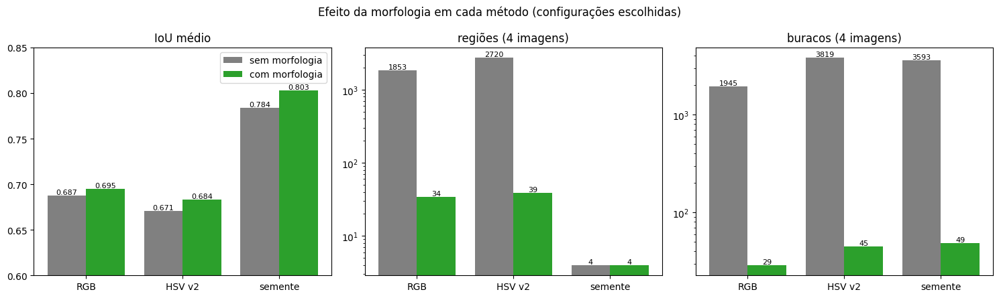

In [72]:
METODOS = list(ESCOLHA)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
for k, (titulo, f, log) in enumerate([('IoU médio', lambda r: np.mean([x['iou'] for x in r.values()]), False),
                                       ('regiões (4 imagens)', lambda r: sum(x['regioes'] for x in r.values()), True),
                                       ('buracos (4 imagens)', lambda r: sum(x['buracos'] for x in r.values()), True)]):
    sem = [f(FINAL[(e, 'sem')]) for e in METODOS]
    com = [f(FINAL[(e, 'com')]) for e in METODOS]
    x = np.arange(len(METODOS))
    b1 = ax[k].bar(x - 0.2, sem, 0.4, color='gray', label='sem morfologia')
    b2 = ax[k].bar(x + 0.2, com, 0.4, color='tab:green', label='com morfologia')
    fmt = '%d' if log else '%.3f'
    ax[k].bar_label(b1, fmt=fmt, fontsize=8); ax[k].bar_label(b2, fmt=fmt, fontsize=8)
    ax[k].set_xticks(x); ax[k].set_xticklabels(METODOS); ax[k].set_title(titulo)
    if log: ax[k].set_yscale('log')
    else: ax[k].set_ylim(0.6, 0.85)
ax[0].legend(); fig.suptitle('Efeito da morfologia em cada método (configurações escolhidas)')
plt.tight_layout(); plt.show()